<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Online_Auto_ml_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DOWNLOADING MARKET DATA
Observations: 2708
Period: 2015-01-02 00:00:00 → 2025-12-31 00:00:00

MARKET CONTEXT FEATURES
Number of context features: 21
Final observations: 2429

Feature list:
01. Momentum_5
02. Momentum_20
03. Momentum_60
04. Momentum_120
05. Distance_MA20
06. Distance_MA50
07. Distance_MA200
08. MA20_MA50_Spread
09. MA50_MA200_Spread
10. Volatility_5
11. Volatility_20
12. Volatility_60
13. Volatility_Ratio
14. RSI_14
15. Volume_Ratio
16. Volume_Change
17. Daily_Range
18. Range_20
19. Drawdown
20. Trend_Score
21. Return_Autocorr_20

TOP CORRELATIONS WITH 20-DAY MOMENTUM
Price
Momentum_20         1.000000
Distance_MA50       0.863806
Distance_MA20       0.855409
Trend_Score         0.751127
RSI_14              0.712364
MA20_MA50_Spread    0.566295
Momentum_60         0.541233
Momentum_5          0.494557
Distance_MA200      0.471100
Volatility_5        0.456414
Name: Momentum_20, dtype: float64

MARKET REGIME DISTRIBUTION
Market_Regime
Bullish Trend / Low Volatility     10

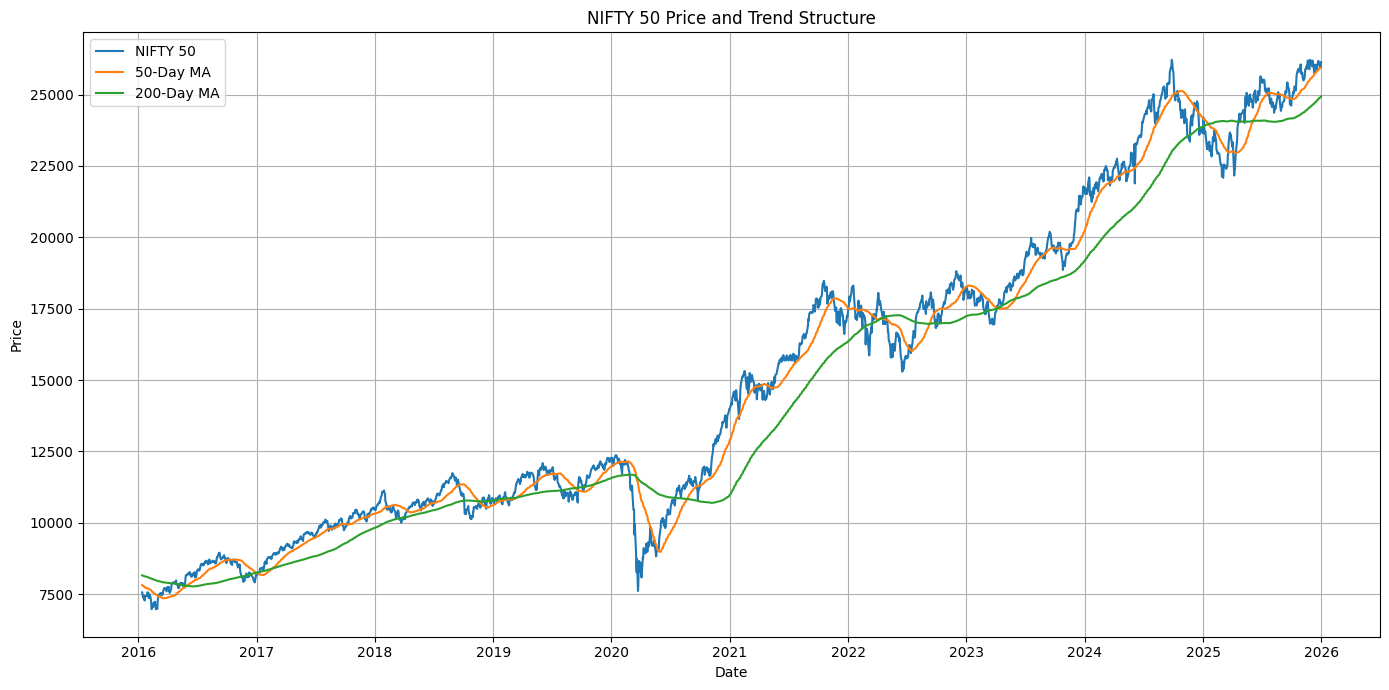

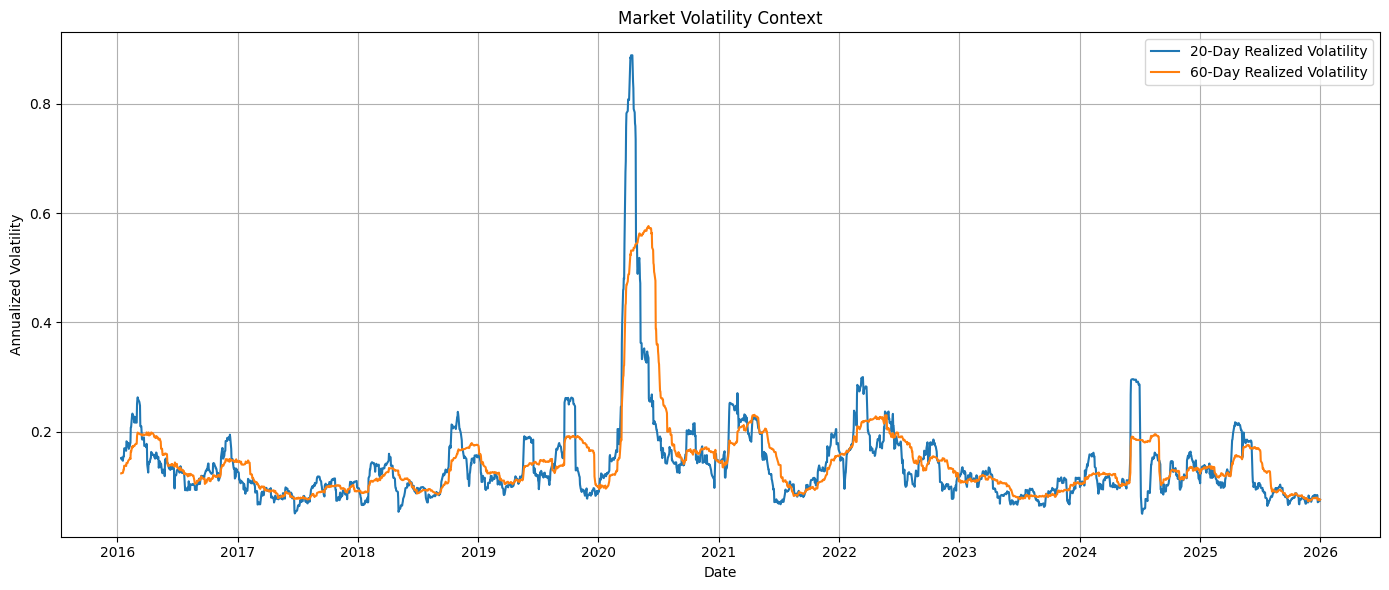

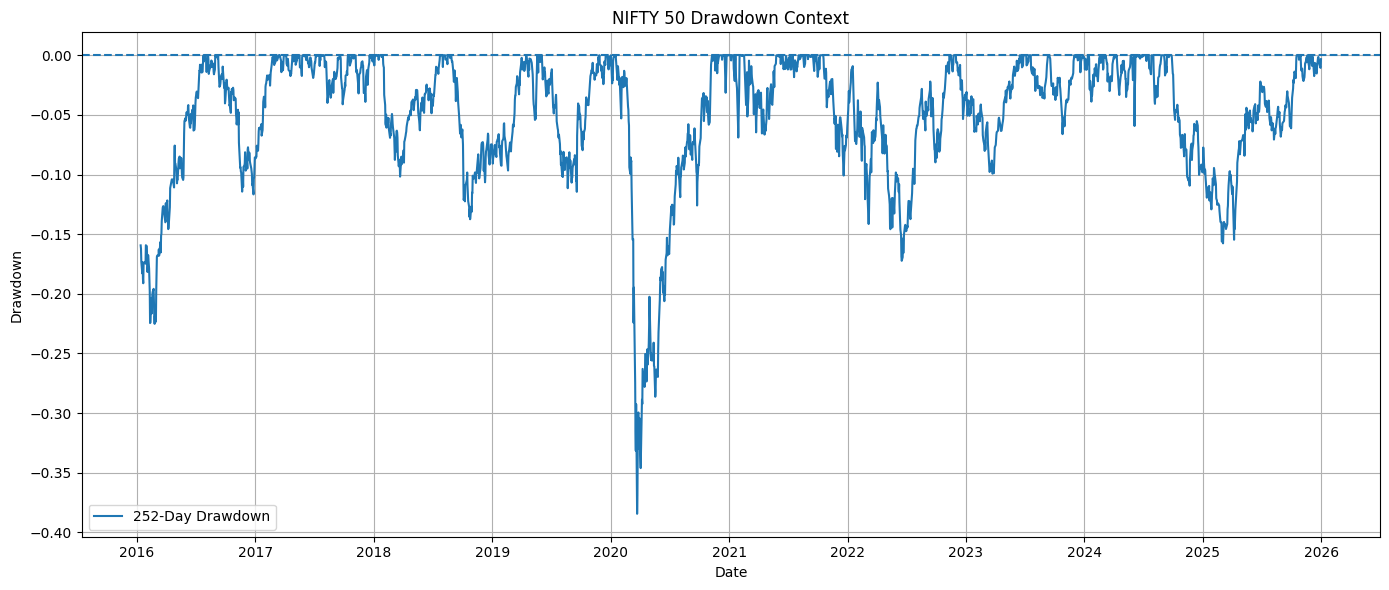


PART 1 COMPLETED
Context features: 21
Observations: 2429
Saved: project2_market_context_dataset.csv

Next:
Part 2 → Build the independent alpha strategies


In [ ]:
# ============================================================
# REGIME-AWARE ALPHA STRATEGY SELECTION
# PART 1: MARKET CONTEXT ENGINE
# ============================================================

# If needed:
# !pip install -q yfinance pandas numpy matplotlib

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf


# ============================================================
# 1. DOWNLOAD MARKET DATA
# ============================================================

TICKER = "^NSEI"

START_DATE = "2015-01-01"

END_DATE = "2026-01-01"


print("=" * 70)
print("DOWNLOADING MARKET DATA")
print("=" * 70)

data = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)


# ============================================================
# 2. HANDLE YFINANCE COLUMN FORMAT
# ============================================================

if isinstance(data.columns, pd.MultiIndex):

    data.columns = data.columns.get_level_values(0)


data = data[
    [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]
].copy()


data.dropna(
    inplace=True
)

data.sort_index(
    inplace=True
)


print(
    "Observations:",
    len(data)
)

print(
    "Period:",
    data.index.min(),
    "→",
    data.index.max()
)


# ============================================================
# 3. DAILY RETURNS
# ============================================================

data["Return_1D"] = (
    data["Close"]
    .pct_change()
)


# ============================================================
# 4. MOMENTUM FEATURES
# ============================================================

data["Momentum_5"] = (
    data["Close"]
    / data["Close"].shift(5)
    - 1
)

data["Momentum_20"] = (
    data["Close"]
    / data["Close"].shift(20)
    - 1
)

data["Momentum_60"] = (
    data["Close"]
    / data["Close"].shift(60)
    - 1
)

data["Momentum_120"] = (
    data["Close"]
    / data["Close"].shift(120)
    - 1
)


# ============================================================
# 5. MOVING AVERAGES
# ============================================================

data["MA_20"] = (
    data["Close"]
    .rolling(20)
    .mean()
)

data["MA_50"] = (
    data["Close"]
    .rolling(50)
    .mean()
)

data["MA_100"] = (
    data["Close"]
    .rolling(100)
    .mean()
)

data["MA_200"] = (
    data["Close"]
    .rolling(200)
    .mean()
)


# ============================================================
# 6. TREND FEATURES
# ============================================================

data["Distance_MA20"] = (
    data["Close"]
    / data["MA_20"]
    - 1
)

data["Distance_MA50"] = (
    data["Close"]
    / data["MA_50"]
    - 1
)

data["Distance_MA200"] = (
    data["Close"]
    / data["MA_200"]
    - 1
)


data["MA20_MA50_Spread"] = (
    data["MA_20"]
    / data["MA_50"]
    - 1
)

data["MA50_MA200_Spread"] = (
    data["MA_50"]
    / data["MA_200"]
    - 1
)


# ============================================================
# 7. REALIZED VOLATILITY
# ============================================================

data["Volatility_5"] = (
    data["Return_1D"]
    .rolling(5)
    .std()
    * np.sqrt(252)
)

data["Volatility_20"] = (
    data["Return_1D"]
    .rolling(20)
    .std()
    * np.sqrt(252)
)

data["Volatility_60"] = (
    data["Return_1D"]
    .rolling(60)
    .std()
    * np.sqrt(252)
)


# ============================================================
# 8. VOLATILITY REGIME
# ============================================================

data["Volatility_Ratio"] = (
    data["Volatility_20"]
    /
    data["Volatility_60"]
)


# ============================================================
# 9. RSI
# ============================================================

delta = (
    data["Close"]
    .diff()
)

gain = (
    delta
    .clip(lower=0)
    .rolling(14)
    .mean()
)

loss = (
    -delta
    .clip(upper=0)
    .rolling(14)
    .mean()
)

rs = (
    gain / loss
)

data["RSI_14"] = (
    100
    - (
        100
        / (1 + rs)
    )
)


# ============================================================
# 10. VOLUME FEATURES
# ============================================================

data["Volume_MA20"] = (
    data["Volume"]
    .rolling(20)
    .mean()
)

data["Volume_Ratio"] = (
    data["Volume"]
    / data["Volume_MA20"]
)

data["Volume_Change"] = (
    data["Volume"]
    .pct_change()
)


# ============================================================
# 11. PRICE RANGE
# ============================================================

data["Daily_Range"] = (
    data["High"]
    - data["Low"]
) / data["Close"]


data["Range_20"] = (
    data["Daily_Range"]
    .rolling(20)
    .mean()
)


# ============================================================
# 12. DRAWDOWN
# ============================================================

data["Rolling_High_252"] = (
    data["Close"]
    .rolling(252)
    .max()
)

data["Drawdown"] = (
    data["Close"]
    / data["Rolling_High_252"]
    - 1
)


# ============================================================
# 13. TREND STRENGTH SCORE
# ============================================================

data["Trend_Score"] = (
    data["Distance_MA20"]
    + data["Distance_MA50"]
    + data["Distance_MA200"]
)


# ============================================================
# 14. RETURN AUTOCORRELATION
# ============================================================

data["Return_Autocorr_20"] = (
    data["Return_1D"]
    .rolling(20)
    .corr(
        data["Return_1D"].shift(1)
    )
)


# ============================================================
# 15. MARKET CONTEXT FEATURES
# ============================================================

context_features = [

    "Momentum_5",
    "Momentum_20",
    "Momentum_60",
    "Momentum_120",

    "Distance_MA20",
    "Distance_MA50",
    "Distance_MA200",

    "MA20_MA50_Spread",
    "MA50_MA200_Spread",

    "Volatility_5",
    "Volatility_20",
    "Volatility_60",

    "Volatility_Ratio",

    "RSI_14",

    "Volume_Ratio",
    "Volume_Change",

    "Daily_Range",
    "Range_20",

    "Drawdown",

    "Trend_Score",

    "Return_Autocorr_20"
]


# ============================================================
# 16. CLEAN DATA
# ============================================================

data = data.replace(
    [np.inf, -np.inf],
    np.nan
)

data.dropna(
    subset=context_features,
    inplace=True
)


# ============================================================
# 17. SUMMARY STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("MARKET CONTEXT FEATURES")
print("=" * 70)

print(
    "Number of context features:",
    len(context_features)
)

print(
    "Final observations:",
    len(data)
)

print("\nFeature list:")

for i, feature in enumerate(
    context_features,
    1
):

    print(
        f"{i:02d}. {feature}"
    )


# ============================================================
# 18. CORRELATION MATRIX
# ============================================================

correlation = (
    data[context_features]
    .corr()
)


print("\n" + "=" * 70)
print("TOP CORRELATIONS WITH 20-DAY MOMENTUM")
print("=" * 70)

print(
    correlation["Momentum_20"]
    .abs()
    .sort_values(
        ascending=False
    )
    .head(10)
)


# ============================================================
# 19. BASIC MARKET REGIME LABELS
# ============================================================
#
# IMPORTANT:
# These labels are for ANALYSIS ONLY.
#
# VW will NOT be given these labels later.
# VW will learn from the raw context.

data["Trend_Regime"] = np.select(

    [

        data["Trend_Score"] > 0.05,

        data["Trend_Score"] < -0.05

    ],

    [

        "Bullish Trend",

        "Bearish Trend"

    ],

    default="Neutral"
)


volatility_median = (
    data["Volatility_20"]
    .rolling(252)
    .median()
)


data["Volatility_Regime"] = np.where(

    data["Volatility_20"]
    >
    volatility_median,

    "High Volatility",

    "Low Volatility"
)


# ============================================================
# 20. COMBINED ANALYTICAL REGIME
# ============================================================

data["Market_Regime"] = (

    data["Trend_Regime"]
    + " / "
    + data["Volatility_Regime"]

)


# ============================================================
# 21. REGIME DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("MARKET REGIME DISTRIBUTION")
print("=" * 70)

regime_distribution = (
    data["Market_Regime"]
    .value_counts()
)

print(
    regime_distribution
)


# ============================================================
# 22. REGIME RETURN ANALYSIS
# ============================================================

regime_returns = (
    data
    .groupby("Market_Regime")["Return_1D"]
    .agg(
        [
            "count",
            "mean",
            "std"
        ]
    )
)


regime_returns["Annualized_Return"] = (
    regime_returns["mean"]
    * 252
)

regime_returns["Annualized_Volatility"] = (
    regime_returns["std"]
    * np.sqrt(252)
)


print("\n" + "=" * 70)
print("REGIME RETURN CHARACTERISTICS")
print("=" * 70)

print(
    regime_returns
)


# ============================================================
# 23. PLOT PRICE + MOVING AVERAGES
# ============================================================

plt.figure(
    figsize=(14, 7)
)

plt.plot(
    data.index,
    data["Close"],
    label="NIFTY 50"
)

plt.plot(
    data.index,
    data["MA_50"],
    label="50-Day MA"
)

plt.plot(
    data.index,
    data["MA_200"],
    label="200-Day MA"
)

plt.title(
    "NIFTY 50 Price and Trend Structure"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Price"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 24. PLOT VOLATILITY
# ============================================================

plt.figure(
    figsize=(14, 6)
)

plt.plot(
    data.index,
    data["Volatility_20"],
    label="20-Day Realized Volatility"
)

plt.plot(
    data.index,
    data["Volatility_60"],
    label="60-Day Realized Volatility"
)

plt.title(
    "Market Volatility Context"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Annualized Volatility"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 25. PLOT DRAWDOWN
# ============================================================

plt.figure(
    figsize=(14, 6)
)

plt.plot(
    data.index,
    data["Drawdown"],
    label="252-Day Drawdown"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "NIFTY 50 Drawdown Context"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Drawdown"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 26. SAVE DATASET
# ============================================================

output_file = (
    "project2_market_context_dataset.csv"
)

data.to_csv(
    output_file
)


# ============================================================
# 27. FINAL CHECK
# ============================================================

print("\n" + "=" * 70)
print("PART 1 COMPLETED")
print("=" * 70)

print(
    "Context features:",
    len(context_features)
)

print(
    "Observations:",
    len(data)
)

print(
    "Saved:",
    output_file
)

print("\nNext:")
print(
    "Part 2 → Build the independent alpha strategies"
)

LOADING MARKET CONTEXT DATA
Observations: 2429
Period: 2016-01-13 00:00:00 → 2025-12-31 00:00:00

INDIVIDUAL STRATEGY PERFORMANCE
           Strategy  CAGR Sharpe Sortino Max Drawdown Hit Ratio Volatility Total Return
           Momentum 9.40%   0.92    0.99      -15.51%    52.11%     10.30%      137.63%
     Mean_Reversion 1.33%   0.18    0.08      -36.36%    42.99%     10.08%       13.61%
Volatility_Adaptive 8.71%   0.92    1.01      -15.28%    52.05%      9.61%      123.49%
          Defensive 6.08%   0.58    0.70      -20.74%    52.92%     11.28%       76.66%

STRATEGY EXPOSURE

Momentum
Average exposure: 64.70%
Days invested: 64.70%

Mean_Reversion
Average exposure: 10.34%
Days invested: 10.34%

Volatility_Adaptive
Average exposure: 61.53%
Days invested: 64.70%

Defensive
Average exposure: 78.75%
Days invested: 78.75%

STRATEGY RETURN CORRELATION
                     Momentum  Mean_Reversion  Volatility_Adaptive  Defensive
Momentum                1.000           0.003             

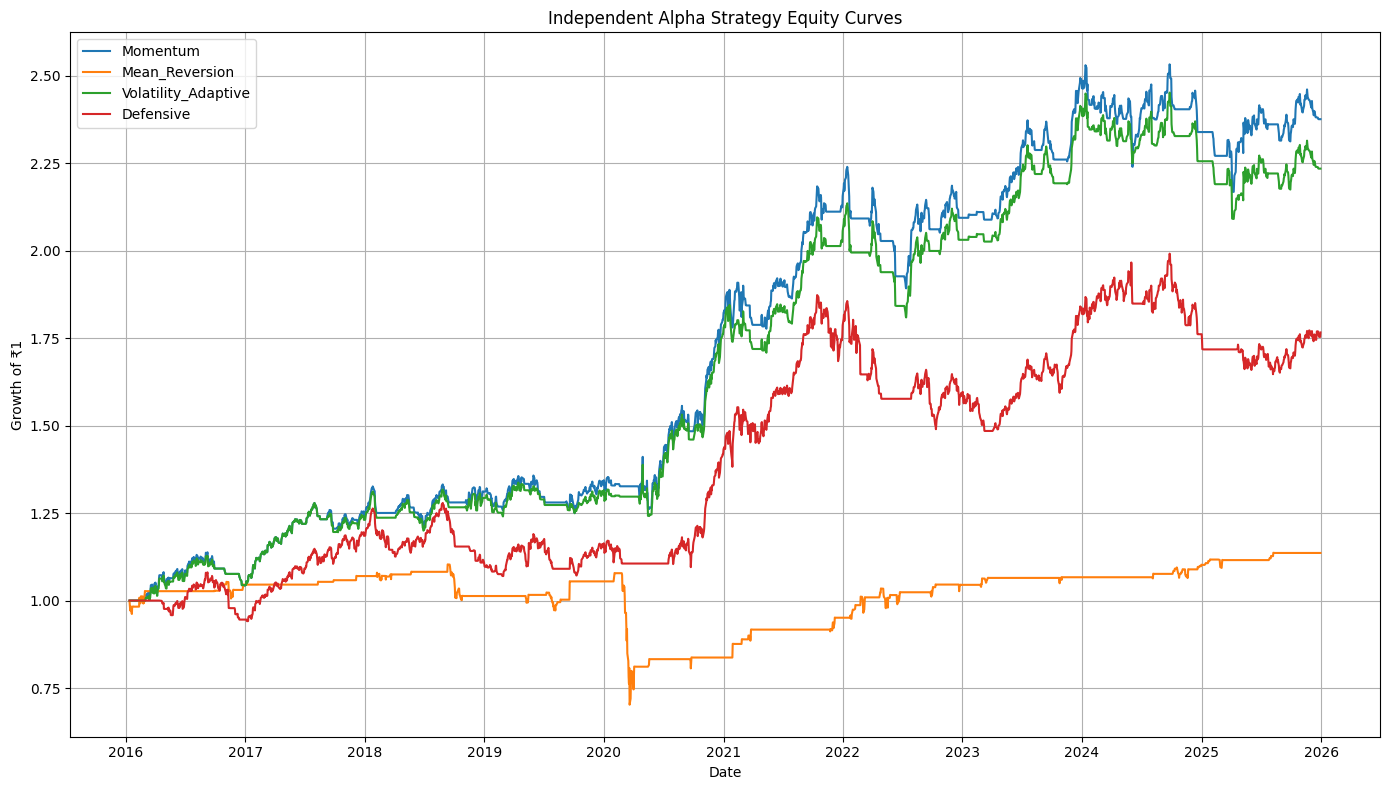

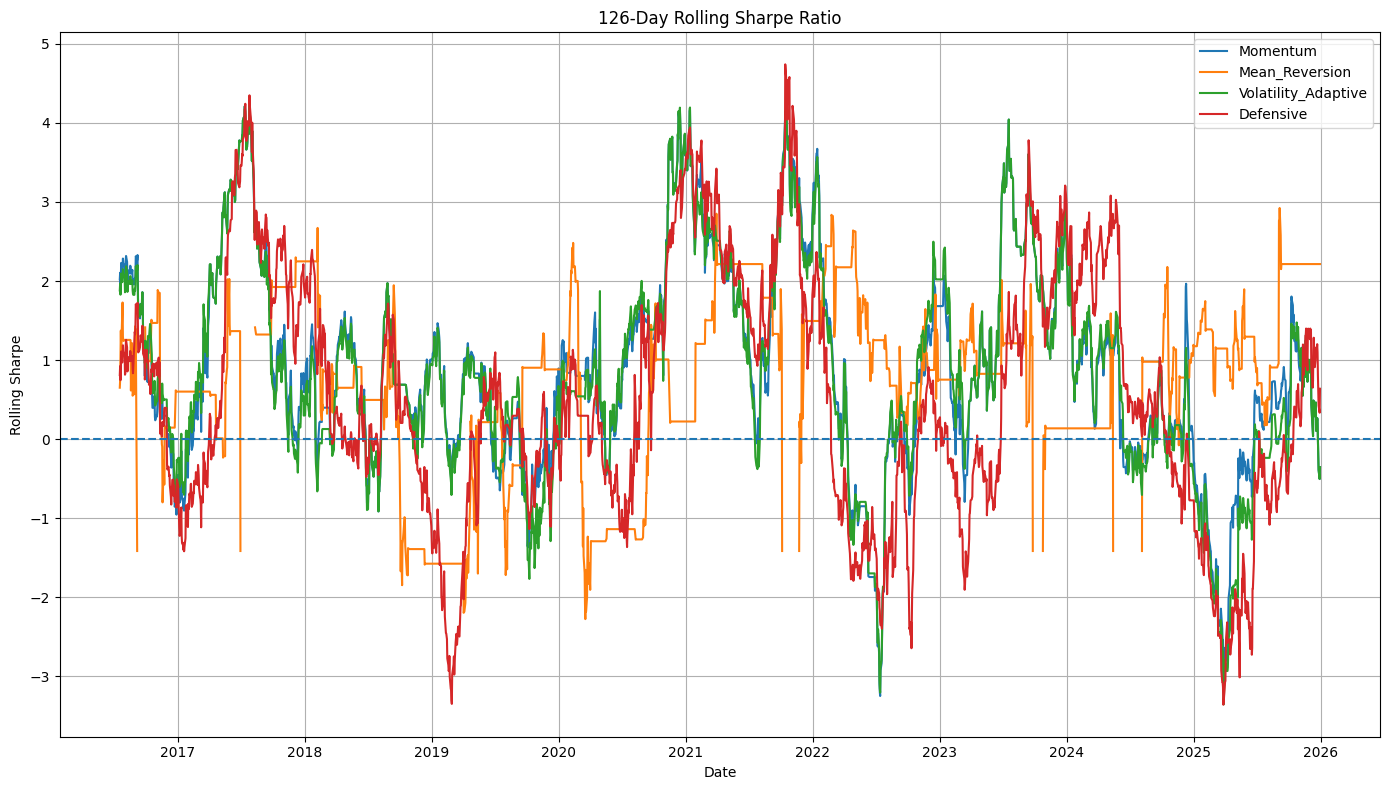


COUNTERFACTUAL BEST STRATEGY FREQUENCY
Best_Strategy
Momentum          52.51%
Mean_Reversion    35.58%
Defensive          11.9%
Name: proportion, dtype: object

PART 2 COMPLETED
Strategies created: 4
1. Momentum
2. Mean Reversion
3. Volatility Adaptive
4. Defensive

Files saved:
project2_strategy_dataset.csv
project2_strategy_returns.csv
project2_strategy_performance.csv
project2_regime_strategy_results.csv
project2_reward_matrix.csv

Next:
Part 3 → Build the Vowpal Wabbit contextual bandit


In [ ]:
# ============================================================
# PROJECT 2
# REGIME-AWARE ALPHA STRATEGY SELECTION
#
# PART 2: INDEPENDENT ALPHA STRATEGIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD PART 1 DATASET
# ============================================================

FILE = "project2_market_context_dataset.csv"

data = pd.read_csv(
    FILE,
    index_col=0,
    parse_dates=True
)

data.sort_index(inplace=True)

print("=" * 70)
print("LOADING MARKET CONTEXT DATA")
print("=" * 70)

print(
    "Observations:",
    len(data)
)

print(
    "Period:",
    data.index.min(),
    "→",
    data.index.max()
)


# ============================================================
# 2. STRATEGY PARAMETERS
# ============================================================

TRANSACTION_COST = 0.0005

# 5 basis points per position change.
#
# We use costs because a strategy selector that constantly
# changes strategies should not receive free trading.


# ============================================================
# 3. HELPER FUNCTION
# ============================================================

def calculate_strategy_returns(
    signal,
    future_return,
    transaction_cost=TRANSACTION_COST
):
    """
    Convert today's signal into tomorrow's strategy return.

    signal:
        +1 = long
         0 = cash

    future_return:
        next-day market return
    """

    signal = pd.Series(
        signal,
        index=data.index
    ).fillna(0)

    future_return = pd.Series(
        future_return,
        index=data.index
    )

    # Position changes

    turnover = (
        signal
        .diff()
        .abs()
        .fillna(
            signal.abs()
        )
    )

    # Trading return

    strategy_return = (
        signal
        * future_return
        -
        turnover
        * transaction_cost
    )

    return strategy_return


# ============================================================
# 4. FUTURE RETURN
# ============================================================

data["Future_Return_1D"] = (
    data["Close"]
    .pct_change()
    .shift(-1)
)


# ============================================================
# STRATEGY 1
# MOMENTUM
# ============================================================

# Basic trend-following strategy.
#
# Long when medium-term momentum is positive.
# Otherwise remain in cash.

data["Momentum_Signal"] = np.where(

    data["Momentum_20"] > 0,

    1,

    0
)


data["Momentum_Return"] = (
    calculate_strategy_returns(

        data["Momentum_Signal"],

        data["Future_Return_1D"]

    )
)


# ============================================================
# STRATEGY 2
# MEAN REVERSION
# ============================================================

# Buy when price is sufficiently below its
# 20-day moving average AND RSI indicates weakness.
#
# Exit when price returns toward its mean.

data["MeanRev_Signal"] = np.where(

    (
        (data["Distance_MA20"] < -0.02)
        &
        (data["RSI_14"] < 40)
    ),

    1,

    0
)


data["MeanRev_Return"] = (
    calculate_strategy_returns(

        data["MeanRev_Signal"],

        data["Future_Return_1D"]

    )
)


# ============================================================
# STRATEGY 3
# VOLATILITY-ADAPTIVE
# ============================================================

# This strategy uses momentum direction but changes
# exposure according to volatility.
#
# Low volatility  -> full exposure
# Moderate        -> half exposure
# Very high       -> cash
#
# Position can therefore be:
#
# 1.0
# 0.5
# 0.0

volatility_ratio = (
    data["Volatility_Ratio"]
)


data["Volatility_Signal"] = np.select(

    [

        (
            (data["Momentum_20"] > 0)
            &
            (volatility_ratio < 1.20)
        ),

        (
            (data["Momentum_20"] > 0)
            &
            (volatility_ratio >= 1.20)
            &
            (volatility_ratio < 1.60)
        )

    ],

    [

        1.0,

        0.5

    ],

    default=0.0
)


data["Volatility_Return"] = (
    calculate_strategy_returns(

        data["Volatility_Signal"],

        data["Future_Return_1D"]

    )
)


# ============================================================
# STRATEGY 4
# DEFENSIVE
# ============================================================

# Defensive strategy:
#
# Stay invested only when the market is above
# its 200-day moving average and volatility is
# not excessively elevated.
#
# Otherwise move to cash.

data["Defensive_Signal"] = np.where(

    (
        (data["Distance_MA200"] > 0)
        &
        (data["Volatility_Ratio"] < 1.50)
    ),

    1,

    0
)


data["Defensive_Return"] = (
    calculate_strategy_returns(

        data["Defensive_Signal"],

        data["Future_Return_1D"]

    )
)


# ============================================================
# 5. REMOVE FINAL NaN
# ============================================================

data.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

data.dropna(
    subset=[
        "Future_Return_1D",
        "Momentum_Return",
        "MeanRev_Return",
        "Volatility_Return",
        "Defensive_Return"
    ],
    inplace=True
)


# ============================================================
# 6. STRATEGY RETURN MATRIX
# ============================================================

strategy_returns = pd.DataFrame({

    "Momentum":
        data["Momentum_Return"],

    "Mean_Reversion":
        data["MeanRev_Return"],

    "Volatility_Adaptive":
        data["Volatility_Return"],

    "Defensive":
        data["Defensive_Return"]

})


# ============================================================
# 7. STRATEGY EQUITY CURVES
# ============================================================

equity_curves = (
    1 + strategy_returns
).cumprod()


# ============================================================
# 8. PERFORMANCE FUNCTIONS
# ============================================================

def calculate_cagr(returns):

    returns = pd.Series(
        returns
    ).dropna()

    equity = (
        1 + returns
    ).cumprod()

    years = (
        len(returns) / 252
    )

    if years <= 0:
        return np.nan

    return (
        equity.iloc[-1]
        ** (1 / years)
    ) - 1


def calculate_sharpe(returns):

    returns = pd.Series(
        returns
    ).dropna()

    if returns.std() == 0:
        return np.nan

    return (
        np.sqrt(252)
        * returns.mean()
        / returns.std()
    )


def calculate_max_drawdown(returns):

    returns = pd.Series(
        returns
    ).dropna()

    equity = (
        1 + returns
    ).cumprod()

    peak = (
        equity
        .cummax()
    )

    drawdown = (
        equity / peak - 1
    )

    return drawdown.min()


def calculate_sortino(returns):

    returns = pd.Series(
        returns
    ).dropna()

    downside = returns[
        returns < 0
    ]

    if downside.std() == 0:
        return np.nan

    return (
        np.sqrt(252)
        * returns.mean()
        / downside.std()
    )


def calculate_hit_ratio(returns):

    returns = pd.Series(
        returns
    ).dropna()

    active = returns[
        returns != 0
    ]

    if len(active) == 0:
        return np.nan

    return (
        (active > 0)
        .mean()
    )


# ============================================================
# 9. STRATEGY PERFORMANCE TABLE
# ============================================================

performance = []


for strategy in strategy_returns.columns:

    r = strategy_returns[
        strategy
    ]

    performance.append({

        "Strategy":
            strategy,

        "CAGR":
            calculate_cagr(r),

        "Sharpe":
            calculate_sharpe(r),

        "Sortino":
            calculate_sortino(r),

        "Max Drawdown":
            calculate_max_drawdown(r),

        "Hit Ratio":
            calculate_hit_ratio(r),

        "Volatility":
            r.std() * np.sqrt(252),

        "Total Return":
            (
                1 + r
            ).prod() - 1

    })


performance_df = pd.DataFrame(
    performance
)


# ============================================================
# 10. PRINT PERFORMANCE
# ============================================================

print("\n" + "=" * 70)

print(
    "INDIVIDUAL STRATEGY PERFORMANCE"
)

print("=" * 70)


print(
    performance_df.to_string(
        index=False,
        formatters={

            "CAGR":
                "{:.2%}".format,

            "Sharpe":
                "{:.2f}".format,

            "Sortino":
                "{:.2f}".format,

            "Max Drawdown":
                "{:.2%}".format,

            "Hit Ratio":
                "{:.2%}".format,

            "Volatility":
                "{:.2%}".format,

            "Total Return":
                "{:.2%}".format
        }
    )
)


# ============================================================
# 11. SIGNAL DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)

print(
    "STRATEGY EXPOSURE"
)

print("=" * 70)


signals = {

    "Momentum":
        data["Momentum_Signal"],

    "Mean_Reversion":
        data["MeanRev_Signal"],

    "Volatility_Adaptive":
        data["Volatility_Signal"],

    "Defensive":
        data["Defensive_Signal"]

}


for name, signal in signals.items():

    print(
        f"\n{name}"
    )

    print(
        "Average exposure:",
        f"{signal.mean():.2%}"
    )

    print(
        "Days invested:",
        f"{(signal > 0).mean():.2%}"
    )


# ============================================================
# 12. CORRELATION BETWEEN STRATEGIES
# ============================================================

print("\n" + "=" * 70)

print(
    "STRATEGY RETURN CORRELATION"
)

print("=" * 70)


strategy_correlation = (
    strategy_returns.corr()
)

print(
    strategy_correlation.round(3)
)


# ============================================================
# 13. REGIME-SPECIFIC PERFORMANCE
# ============================================================

print("\n" + "=" * 70)

print(
    "REGIME-SPECIFIC STRATEGY PERFORMANCE"
)

print("=" * 70)


regime_strategy_results = []


for regime in (
    data["Market_Regime"]
    .unique()
):

    regime_mask = (
        data["Market_Regime"]
        == regime
    )


    for strategy in (
        strategy_returns.columns
    ):

        r = strategy_returns.loc[
            regime_mask,
            strategy
        ]

        regime_strategy_results.append({

            "Regime":
                regime,

            "Strategy":
                strategy,

            "Mean Return":
                r.mean(),

            "Sharpe":
                calculate_sharpe(r),

            "Hit Ratio":
                calculate_hit_ratio(r),

            "Observations":
                len(r)

        })


regime_results_df = pd.DataFrame(
    regime_strategy_results
)


print(
    regime_results_df.to_string(
        index=False,
        formatters={

            "Mean Return":
                "{:.4%}".format,

            "Sharpe":
                "{:.2f}".format,

            "Hit Ratio":
                "{:.2%}".format

        }
    )
)


# ============================================================
# 14. BEST STRATEGY BY REGIME
# ============================================================

print("\n" + "=" * 70)

print(
    "BEST STRATEGY BY MARKET REGIME"
)

print("=" * 70)


best_by_regime = (
    regime_results_df
    .sort_values(
        "Sharpe",
        ascending=False
    )
    .groupby(
        "Regime"
    )
    .first()
)


print(
    best_by_regime[
        [
            "Strategy",
            "Sharpe",
            "Mean Return",
            "Hit Ratio",
            "Observations"
        ]
    ].to_string()
)


# ============================================================
# 15. EQUITY CURVES
# ============================================================

plt.figure(
    figsize=(14, 8)
)

for strategy in (
    equity_curves.columns
):

    plt.plot(
        equity_curves.index,
        equity_curves[strategy],
        label=strategy
    )


plt.title(
    "Independent Alpha Strategy Equity Curves"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Growth of ₹1"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 16. ROLLING SHARPE
# ============================================================

rolling_window = 126


plt.figure(
    figsize=(14, 8)
)


for strategy in (
    strategy_returns.columns
):

    rolling_sharpe = (

        strategy_returns[strategy]
        .rolling(rolling_window)
        .mean()

        /

        strategy_returns[strategy]
        .rolling(rolling_window)
        .std()

        *

        np.sqrt(252)

    )

    plt.plot(
        rolling_sharpe,
        label=strategy
    )


plt.axhline(
    0,
    linestyle="--"
)


plt.title(
    "126-Day Rolling Sharpe Ratio"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Rolling Sharpe"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 17. CREATE COUNTERFACTUAL REWARD MATRIX
# ============================================================

reward_matrix = pd.DataFrame({

    "Context_Trend":
        data["Trend_Score"],

    "Context_Volatility":
        data["Volatility_20"],

    "Context_RSI":
        data["RSI_14"],

    "Context_Momentum":
        data["Momentum_20"],

    "Momentum":
        strategy_returns["Momentum"],

    "Mean_Reversion":
        strategy_returns["Mean_Reversion"],

    "Volatility_Adaptive":
        strategy_returns["Volatility_Adaptive"],

    "Defensive":
        strategy_returns["Defensive"]

}, index=data.index)


# ============================================================
# 18. BEST COUNTERFACTUAL ACTION
# ============================================================

strategy_columns = [
    "Momentum",
    "Mean_Reversion",
    "Volatility_Adaptive",
    "Defensive"
]


reward_matrix[
    "Best_Strategy"
] = (
    reward_matrix[
        strategy_columns
    ]
    .idxmax(
        axis=1
    )
)


reward_matrix[
    "Best_Reward"
] = (
    reward_matrix[
        strategy_columns
    ]
    .max(
        axis=1
    )
)


# ============================================================
# 19. BEST STRATEGY FREQUENCY
# ============================================================

print("\n" + "=" * 70)

print(
    "COUNTERFACTUAL BEST STRATEGY FREQUENCY"
)

print("=" * 70)


print(
    reward_matrix[
        "Best_Strategy"
    ].value_counts(
        normalize=True
    ).mul(100)
    .round(2)
    .astype(str)
    .add("%")
)


# ============================================================
# 20. SAVE OUTPUTS
# ============================================================

data.to_csv(
    "project2_strategy_dataset.csv"
)

strategy_returns.to_csv(
    "project2_strategy_returns.csv"
)

performance_df.to_csv(
    "project2_strategy_performance.csv",
    index=False
)

regime_results_df.to_csv(
    "project2_regime_strategy_results.csv",
    index=False
)

reward_matrix.to_csv(
    "project2_reward_matrix.csv"
)


# ============================================================
# 21. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)

print(
    "PART 2 COMPLETED"
)

print("=" * 70)

print(
    "Strategies created: 4"
)

print(
    "1. Momentum"
)

print(
    "2. Mean Reversion"
)

print(
    "3. Volatility Adaptive"
)

print(
    "4. Defensive"
)

print("\nFiles saved:")

print(
    "project2_strategy_dataset.csv"
)

print(
    "project2_strategy_returns.csv"
)

print(
    "project2_strategy_performance.csv"
)

print(
    "project2_regime_strategy_results.csv"
)

print(
    "project2_reward_matrix.csv"
)

print("\nNext:")

print(
    "Part 3 → Build the Vowpal Wabbit contextual bandit"
)

In [ ]:
!pip install -q vowpalwabbit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 14.5 MB/s eta 0:00:00


LOADING STRATEGY DATA
Observations: 2428
Period: 2016-01-13 00:00:00 → 2025-12-30 00:00:00

All required columns found.
Clean observations: 2428

TRAIN / TEST SPLIT
Training observations: 1699
Testing observations: 729
Training period: 2016-01-13 00:00:00 → 2023-01-04 00:00:00
Testing period: 2023-01-05 00:00:00 → 2025-12-30 00:00:00

VW OUTPUT CHECK
Raw prediction: [0.25, 0.25, 0.25, 0.25]
Parsed probabilities: [0.25 0.25 0.25 0.25]
Probability sum: 1.0

TRAINING VOWPAL WABBIT
Training completed.

OUT-OF-SAMPLE TEST

FINAL VW PERFORMANCE
               Model   CAGR Sharpe Max Drawdown Hit Ratio Total Return Volatility
VW Contextual Bandit  0.97%   0.15      -19.20%    50.69%        2.84%      9.18%
              Oracle 98.38%  10.12       -0.05%    99.47%      625.42%      6.80%
          Buy & Hold 13.77%   1.13      -15.77%    54.40%       45.23%     12.09%
            Momentum  4.46%   0.51      -14.39%    51.11%       13.46%      9.40%
      Mean Reversion  2.93%   0.87       -2.7

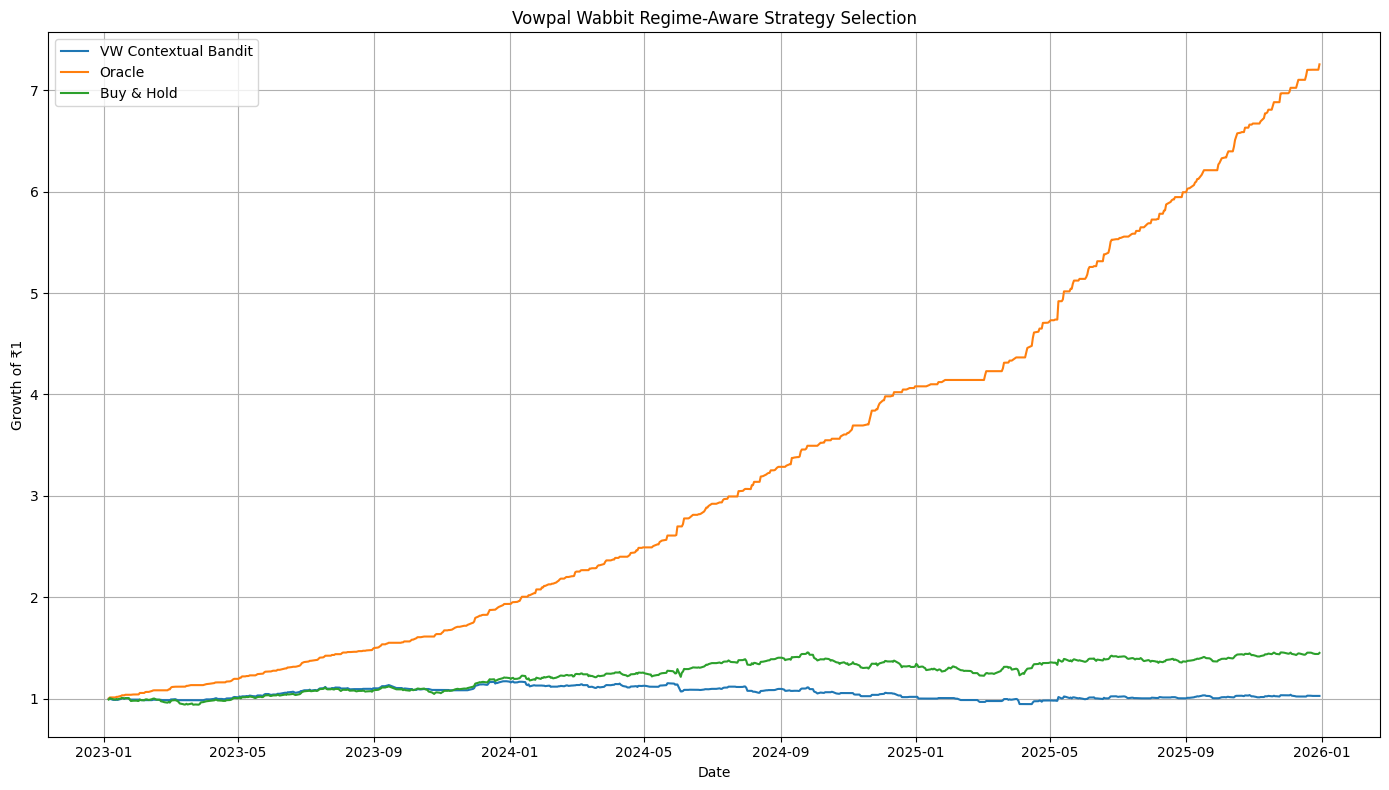

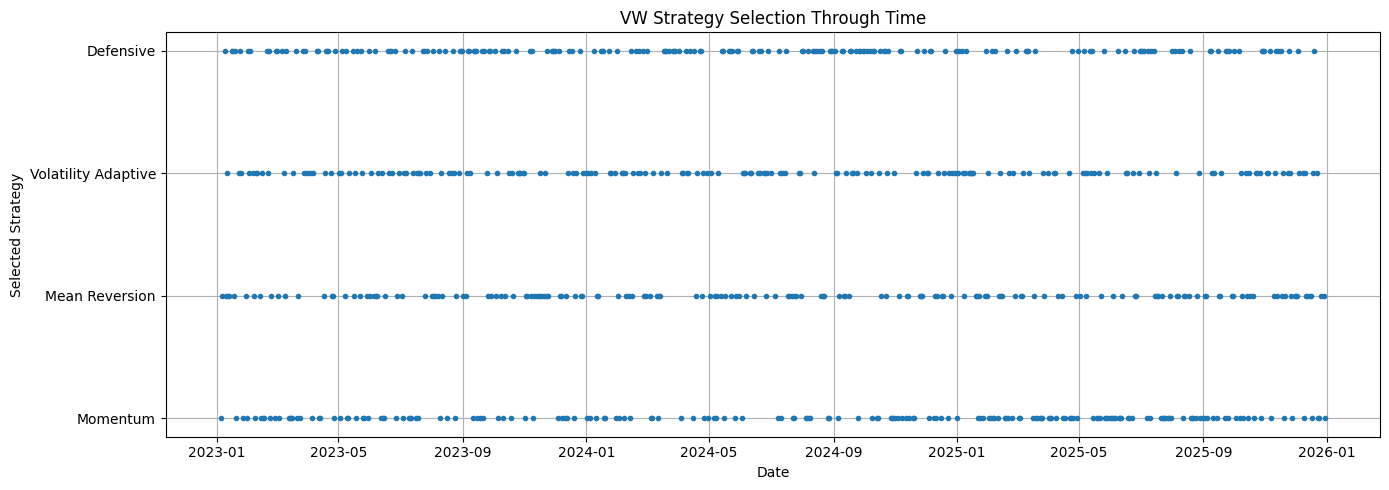


AVERAGE STRATEGY RETURN BY MARKET REGIME
                                 Momentum  Mean Reversion  \
Market_Regime                                               
Bearish Trend / High Volatility  -0.00036         0.00129   
Bearish Trend / Low Volatility    0.00000         0.00080   
Bullish Trend / High Volatility  -0.00024         0.00007   
Bullish Trend / Low Volatility    0.00057         0.00000   
Neutral / High Volatility         0.00054        -0.00034   
Neutral / Low Volatility          0.00014         0.00016   

                                 Volatility Adaptive  Defensive       VW  
Market_Regime                                                             
Bearish Trend / High Volatility             -0.00066    0.00021 -0.00087  
Bearish Trend / Low Volatility               0.00000   -0.00003  0.00014  
Bullish Trend / High Volatility             -0.00027   -0.00014 -0.00047  
Bullish Trend / Low Volatility               0.00057    0.00050  0.00048  
Neutral / High Vola

In [ ]:
# ============================================================
# PROJECT 2
# REGIME-AWARE ALPHA STRATEGY SELECTION
#
# PART 3: VOWPAL WABBIT CONTEXTUAL BANDIT
# ============================================================


# ============================================================
# 0. INSTALLATION
# ============================================================

# Run ONLY if VW is not installed:
# !pip install -q vowpalwabbit


# ============================================================
# 1. IMPORTS
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vowpalwabbit import Workspace


# ============================================================
# 2. LOAD STRATEGY DATA
# ============================================================

FILE = "project2_strategy_dataset.csv"

data = pd.read_csv(
    FILE,
    index_col=0,
    parse_dates=True
)

data.sort_index(
    inplace=True
)


print("=" * 75)
print("LOADING STRATEGY DATA")
print("=" * 75)

print(
    "Observations:",
    len(data)
)

print(
    "Period:",
    data.index.min(),
    "→",
    data.index.max()
)


# ============================================================
# 3. STRATEGY DEFINITIONS
# ============================================================

strategies = [

    "Momentum",

    "Mean_Reversion",

    "Volatility_Adaptive",

    "Defensive"

]


# Actual return columns in Part 2 dataset

strategy_return_columns = {

    "Momentum":
        "Momentum_Return",

    "Mean_Reversion":
        "MeanRev_Return",

    "Volatility_Adaptive":
        "Volatility_Return",

    "Defensive":
        "Defensive_Return"

}


# VW action mapping

ACTION_TO_STRATEGY = {

    1: "Momentum",

    2: "Mean_Reversion",

    3: "Volatility_Adaptive",

    4: "Defensive"

}


STRATEGY_TO_ACTION = {

    strategy: action

    for action, strategy
    in ACTION_TO_STRATEGY.items()

}


N_ACTIONS = 4


# ============================================================
# 4. MARKET CONTEXT FEATURES
# ============================================================

context_features = [

    "Momentum_5",

    "Momentum_20",

    "Momentum_60",

    "Momentum_120",

    "Distance_MA20",

    "Distance_MA50",

    "Distance_MA200",

    "MA20_MA50_Spread",

    "MA50_MA200_Spread",

    "Volatility_5",

    "Volatility_20",

    "Volatility_60",

    "Volatility_Ratio",

    "RSI_14",

    "Volume_Ratio",

    "Volume_Change",

    "Daily_Range",

    "Range_20",

    "Drawdown",

    "Trend_Score",

    "Return_Autocorr_20"

]


# ============================================================
# 5. VERIFY COLUMNS
# ============================================================

required_columns = (

    context_features

    +

    list(
        strategy_return_columns.values()
    )

)


missing = [

    column

    for column in required_columns

    if column not in data.columns

]


if missing:

    raise ValueError(

        "Missing columns: "
        + str(missing)

    )


print("\nAll required columns found.")


# ============================================================
# 6. CLEAN DATA
# ============================================================

data = data.replace(

    [np.inf, -np.inf],

    np.nan

)


data.dropna(

    subset=required_columns,

    inplace=True

)


print(

    "Clean observations:",

    len(data)

)


# ============================================================
# 7. TRAIN / TEST SPLIT
# ============================================================

split = int(

    len(data) * 0.70

)


train = data.iloc[
    :split
].copy()


test = data.iloc[
    split:
].copy()


print("\n" + "=" * 75)
print("TRAIN / TEST SPLIT")
print("=" * 75)

print(

    "Training observations:",

    len(train)

)

print(

    "Testing observations:",

    len(test)

)

print(

    "Training period:",

    train.index.min(),

    "→",

    train.index.max()

)

print(

    "Testing period:",

    test.index.min(),

    "→",

    test.index.max()

)


# ============================================================
# 8. CREATE VOWPAL WABBIT
# ============================================================

vw = Workspace(

    "--cb_explore_adf "

    "--epsilon 0.10 "

    "--learning_rate 0.05 "

    "--power_t 0 "

    "--quiet"

)


# ============================================================
# 9. CREATE CONTEXT STRING
# ============================================================

def create_context(row):

    feature_values = []


    for feature in context_features:

        value = float(
            row[feature]
        )


        if not np.isfinite(value):

            value = 0.0


        feature_values.append(

            f"{feature}:{value:.8f}"

        )


    feature_string = " ".join(

        feature_values

    )


    lines = [

        f"shared | {feature_string}",

        "1 | action_1",

        "2 | action_2",

        "3 | action_3",

        "4 | action_4"

    ]


    return "\n".join(lines)


# ============================================================
# 10. ROBUST VW PROBABILITY PARSER
# ============================================================

def get_probabilities(prediction):

    """
    Handles multiple Vowpal Wabbit return formats.

    Possible outputs include:

    [p1, p2, p3, p4]

    or

    [(action, probability), ...]

    """

    # --------------------------------------------------------
    # Convert prediction into a NumPy array where possible
    # --------------------------------------------------------

    try:

        arr = np.asarray(
            prediction,
            dtype=float
        )

    except:

        arr = None


    # --------------------------------------------------------
    # CASE 1
    #
    # VW returns direct probability vector
    #
    # Example:
    #
    # [0.20, 0.30, 0.25, 0.25]
    # --------------------------------------------------------

    if (

        arr is not None

        and

        arr.ndim == 1

        and

        len(arr) == N_ACTIONS

    ):

        probabilities = arr.astype(
            float
        )


    # --------------------------------------------------------
    # CASE 2
    #
    # VW returns action-probability pairs
    # --------------------------------------------------------

    else:

        probabilities = np.zeros(
            N_ACTIONS,
            dtype=float
        )


        try:

            for item in prediction:

                if (

                    isinstance(
                        item,
                        (tuple, list)
                    )

                    and

                    len(item) >= 2

                ):

                    action = int(
                        item[0]
                    )

                    probability = float(
                        item[1]
                    )


                    if (

                        1
                        <= action
                        <= N_ACTIONS

                    ):

                        probabilities[
                            action - 1
                        ] = probability

        except:

            pass


    # ========================================================
    # SAFETY
    # ========================================================

    probabilities = np.nan_to_num(

        probabilities,

        nan=1.0 / N_ACTIONS,

        posinf=1.0 / N_ACTIONS,

        neginf=1.0 / N_ACTIONS

    )


    probabilities = np.clip(

        probabilities,

        1e-6,

        None

    )


    probabilities = (

        probabilities
        /
        probabilities.sum()

    )


    return probabilities


# ============================================================
# 11. CHECK VW OUTPUT BEFORE TRAINING
# ============================================================

test_context = create_context(
    train.iloc[0]
)


test_prediction = vw.predict(
    test_context
)


test_probabilities = get_probabilities(
    test_prediction
)


print("\n" + "=" * 75)
print("VW OUTPUT CHECK")
print("=" * 75)

print(
    "Raw prediction:",
    test_prediction
)

print(
    "Parsed probabilities:",
    test_probabilities
)

print(
    "Probability sum:",
    test_probabilities.sum()
)


# ============================================================
# 12. TRAIN VW
# ============================================================

print("\n" + "=" * 75)
print("TRAINING VOWPAL WABBIT")
print("=" * 75)


training_actions = []

training_rewards = []


for timestamp, row in train.iterrows():

    # --------------------------------------------------------
    # Market context
    # --------------------------------------------------------

    context = create_context(
        row
    )


    # --------------------------------------------------------
    # VW predicts strategy probabilities
    # --------------------------------------------------------

    prediction = vw.predict(
        context
    )


    probabilities = get_probabilities(
        prediction
    )


    # --------------------------------------------------------
    # Sample strategy
    # --------------------------------------------------------

    chosen_action = np.random.choice(

        np.arange(
            1,
            N_ACTIONS + 1
        ),

        p=probabilities

    )


    chosen_probability = (

        probabilities[
            chosen_action - 1
        ]

    )


    chosen_strategy = (

        ACTION_TO_STRATEGY[
            chosen_action
        ]

    )


    # --------------------------------------------------------
    # OBSERVE ONLY CHOSEN STRATEGY RETURN
    # --------------------------------------------------------

    reward_column = (

        strategy_return_columns[
            chosen_strategy
        ]

    )


    reward = float(

        row[
            reward_column
        ]

    )


    # --------------------------------------------------------
    # VW uses COST
    #
    # Reward  +0.01
    # becomes Cost -0.01
    #
    # Reward  -0.01
    # becomes Cost +0.01
    # --------------------------------------------------------

    cost = -reward


    # --------------------------------------------------------
    # Contextual bandit label
    #
    # action:cost:probability
    # --------------------------------------------------------

    label = (

        f"{chosen_action}:"
        f"{cost:.8f}:"
        f"{chosen_probability:.8f}"

    )


    labeled_example = (

        f"{label}\n"
        f"{context}"

    )


    # --------------------------------------------------------
    # ONLINE LEARNING
    # --------------------------------------------------------

    vw.learn(
        labeled_example
    )


    training_actions.append(
        chosen_action
    )

    training_rewards.append(
        reward
    )


print(
    "Training completed."
)


# ============================================================
# 13. OUT-OF-SAMPLE TEST
# ============================================================

print("\n" + "=" * 75)
print("OUT-OF-SAMPLE TEST")
print("=" * 75)


results = []


for timestamp, row in test.iterrows():

    # --------------------------------------------------------
    # Context
    # --------------------------------------------------------

    context = create_context(
        row
    )


    # --------------------------------------------------------
    # VW prediction
    # --------------------------------------------------------

    prediction = vw.predict(
        context
    )


    probabilities = get_probabilities(
        prediction
    )


    # --------------------------------------------------------
    # Select strategy
    # --------------------------------------------------------

    chosen_action = np.random.choice(

        np.arange(
            1,
            N_ACTIONS + 1
        ),

        p=probabilities

    )


    chosen_probability = (

        probabilities[
            chosen_action - 1
        ]

    )


    chosen_strategy = (

        ACTION_TO_STRATEGY[
            chosen_action
        ]

    )


    # --------------------------------------------------------
    # REALIZED RETURN
    # --------------------------------------------------------

    reward_column = (

        strategy_return_columns[
            chosen_strategy
        ]

    )


    realized_return = float(

        row[
            reward_column
        ]

    )


    # --------------------------------------------------------
    # BEST STRATEGY WITH HINDSIGHT
    # --------------------------------------------------------

    strategy_returns_today = {

        strategy:

            float(
                row[
                    strategy_return_columns[
                        strategy
                    ]
                ]
            )

        for strategy in strategies

    }


    best_strategy = max(

        strategy_returns_today,

        key=strategy_returns_today.get

    )


    best_return = (

        strategy_returns_today[
            best_strategy
        ]

    )


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    results.append({

        "Date":
            timestamp,

        "Chosen_Action":
            chosen_action,

        "Chosen_Strategy":
            chosen_strategy,

        "Selection_Probability":
            chosen_probability,

        "Realized_Return":
            realized_return,

        "Momentum_Return":
            strategy_returns_today[
                "Momentum"
            ],

        "Mean_Reversion_Return":
            strategy_returns_today[
                "Mean_Reversion"
            ],

        "Volatility_Adaptive_Return":
            strategy_returns_today[
                "Volatility_Adaptive"
            ],

        "Defensive_Return":
            strategy_returns_today[
                "Defensive"
            ],

        "Best_Strategy":
            best_strategy,

        "Best_Return":
            best_return,

        "Market_Regime":
            row[
                "Market_Regime"
            ]

    })


    # --------------------------------------------------------
    # NO LEARNING HERE
    #
    # Test period remains completely out-of-sample.
    # --------------------------------------------------------


# ============================================================
# 14. RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
)


results_df.set_index(
    "Date",
    inplace=True
)


# ============================================================
# 15. EQUITY CURVES
# ============================================================

results_df[
    "VW_Equity"
] = (

    1
    +
    results_df[
        "Realized_Return"
    ]

).cumprod()


results_df[
    "Oracle_Equity"
] = (

    1
    +
    results_df[
        "Best_Return"
    ]

).cumprod()


# ============================================================
# 16. BUY & HOLD
# ============================================================

if "Future_Return_1D" in test.columns:

    buy_hold_return = (

        test[
            "Future_Return_1D"
        ]

        .reindex(
            results_df.index
        )

        .fillna(0)

    )

else:

    buy_hold_return = (

        test[
            "Close"
        ]

        .pct_change()

        .shift(-1)

        .reindex(
            results_df.index
        )

        .fillna(0)

    )


results_df[
    "BuyHold_Return"
] = buy_hold_return


results_df[
    "BuyHold_Equity"
] = (

    1
    +
    results_df[
        "BuyHold_Return"
    ]

).cumprod()


# ============================================================
# 17. PERFORMANCE FUNCTIONS
# ============================================================

def calculate_cagr(
    returns
):

    returns = pd.Series(
        returns
    ).dropna()


    equity = (

        1 + returns

    ).cumprod()


    years = (

        len(returns)
        /
        252

    )


    if years <= 0:

        return np.nan


    return (

        equity.iloc[-1]
        **
        (1 / years)

    ) - 1


def calculate_sharpe(
    returns
):

    returns = pd.Series(
        returns
    ).dropna()


    if returns.std() == 0:

        return np.nan


    return (

        np.sqrt(252)
        *
        returns.mean()
        /
        returns.std()

    )


def calculate_max_drawdown(
    returns
):

    returns = pd.Series(
        returns
    ).dropna()


    equity = (

        1 + returns

    ).cumprod()


    peak = equity.cummax()


    drawdown = (

        equity
        /
        peak
        - 1

    )


    return drawdown.min()


def calculate_hit_ratio(
    returns
):

    returns = pd.Series(
        returns
    ).dropna()


    active = returns[
        returns != 0
    ]


    if len(active) == 0:

        return np.nan


    return (

        active > 0

    ).mean()


# ============================================================
# 18. PERFORMANCE COMPARISON
# ============================================================

comparison_returns = {

    "VW Contextual Bandit":
        results_df[
            "Realized_Return"
        ],

    "Oracle":
        results_df[
            "Best_Return"
        ],

    "Buy & Hold":
        results_df[
            "BuyHold_Return"
        ],

    "Momentum":
        results_df[
            "Momentum_Return"
        ],

    "Mean Reversion":
        results_df[
            "Mean_Reversion_Return"
        ],

    "Volatility Adaptive":
        results_df[
            "Volatility_Adaptive_Return"
        ],

    "Defensive":
        results_df[
            "Defensive_Return"
        ]

}


performance = []


for model, returns in (

    comparison_returns.items()

):

    performance.append({

        "Model":
            model,

        "CAGR":
            calculate_cagr(
                returns
            ),

        "Sharpe":
            calculate_sharpe(
                returns
            ),

        "Max Drawdown":
            calculate_max_drawdown(
                returns
            ),

        "Hit Ratio":
            calculate_hit_ratio(
                returns
            ),

        "Total Return":
            (
                1 + returns
            ).prod() - 1,

        "Volatility":
            returns.std()
            *
            np.sqrt(252)

    })


performance_df = pd.DataFrame(
    performance
)


# ============================================================
# 19. FINAL PERFORMANCE
# ============================================================

print("\n" + "=" * 75)
print("FINAL VW PERFORMANCE")
print("=" * 75)


print(

    performance_df.to_string(

        index=False,

        formatters={

            "CAGR":
                "{:.2%}".format,

            "Sharpe":
                "{:.2f}".format,

            "Max Drawdown":
                "{:.2%}".format,

            "Hit Ratio":
                "{:.2%}".format,

            "Total Return":
                "{:.2%}".format,

            "Volatility":
                "{:.2%}".format

        }

    )

)


# ============================================================
# 20. STRATEGY SELECTION FREQUENCY
# ============================================================

print("\n" + "=" * 75)
print("VW STRATEGY SELECTION FREQUENCY")
print("=" * 75)


selection_frequency = (

    results_df[
        "Chosen_Strategy"
    ]

    .value_counts(
        normalize=True
    )

    * 100

)


print(
    selection_frequency.round(2)
)


# # ============================================================
# 21. STRATEGY SELECTION BY REGIME

21# # ============================================================
# PART 21 ONWARD
# ROBUST VERSION: AUTOMATIC STRATEGY COLUMN DETECTION
# ============================================================

print("\n" + "=" * 75)
print("DETECTING STRATEGY RETURN COLUMNS")
print("=" * 75)

# ------------------------------------------------------------
# Automatically identify the return columns that actually
# exist in results_df
# ------------------------------------------------------------

available_columns = list(results_df.columns)

print("\nAvailable strategy-related columns:")

for col in available_columns:
    if "Return" in col:
        print("  ", col)


# ------------------------------------------------------------
# IMPORTANT:
# results_df already contains the strategy return columns
# created during Part 20.
#
# Detect them by matching the strategy names.
# ------------------------------------------------------------

def find_return_column(
    dataframe,
    keywords
):

    candidates = []

    for col in dataframe.columns:

        col_lower = col.lower()

        if "return" not in col_lower:
            continue

        if all(
            keyword.lower() in col_lower
            for keyword in keywords
        ):

            candidates.append(col)


    if len(candidates) == 0:

        return None

    return candidates[0]


# ------------------------------------------------------------
# Detect each strategy
# ------------------------------------------------------------

detected_columns = {

    "Momentum":
        find_return_column(
            results_df,
            ["momentum"]
        ),

    "Mean_Reversion":
        find_return_column(
            results_df,
            ["mean"]
        ),

    "Volatility_Adaptive":
        find_return_column(
            results_df,
            ["volatility"]
        ),

    "Defensive":
        find_return_column(
            results_df,
            ["defensive"]
        )

}


print("\nDetected mapping:")

for strategy, column in detected_columns.items():

    print(
        f"{strategy:25s} → {column}"
    )


# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

missing = [

    strategy

    for strategy, column
    in detected_columns.items()

    if column is None

]


if missing:

    raise ValueError(

        "Could not automatically identify: "
        + str(missing)
        + "\n\nAvailable columns:\n"
        + str(list(results_df.columns))

    )


# ============================================================
# 21. STRATEGY SELECTION BY REGIME
# ============================================================

print("\n" + "=" * 75)
print("VW STRATEGY SELECTION BY REGIME")
print("=" * 75)


regime_selection = pd.crosstab(

    results_df[
        "Market_Regime"
    ],

    results_df[
        "Chosen_Strategy"
    ],

    normalize="index"

) * 100


print(
    regime_selection.round(2)
)


# ============================================================
# 22. PERFORMANCE BY REGIME
# ============================================================

regime_performance = []


for regime in results_df[
    "Market_Regime"
].unique():

    subset = results_df[
        results_df[
            "Market_Regime"
        ] == regime
    ]


    # --------------------------------------------------------
    # Calculate mean return for every strategy
    # --------------------------------------------------------

    strategy_means = {}

    for strategy, column in detected_columns.items():

        strategy_means[
            strategy
        ] = subset[
            column
        ].mean()


    # --------------------------------------------------------
    # Identify best strategy
    # --------------------------------------------------------

    best_strategy = max(

        strategy_means,

        key=strategy_means.get

    )


    regime_performance.append({

        "Regime":
            regime,

        "Observations":
            len(subset),

        "VW_Mean_Return":
            subset[
                "Realized_Return"
            ].mean(),

        "VW_Sharpe":
            calculate_sharpe(
                subset[
                    "Realized_Return"
                ]
            ),

        "VW_Hit_Ratio":
            calculate_hit_ratio(
                subset[
                    "Realized_Return"
                ]
            ),

        "Best_Strategy":
            best_strategy,

        "Best_Strategy_Return":
            strategy_means[
                best_strategy
            ]

    })


regime_performance_df = pd.DataFrame(
    regime_performance
)


print("\n" + "=" * 75)
print("VW PERFORMANCE BY REGIME")
print("=" * 75)


print(

    regime_performance_df.to_string(

        index=False,

        formatters={

            "VW_Mean_Return":
                "{:.4%}".format,

            "VW_Sharpe":
                "{:.2f}".format,

            "VW_Hit_Ratio":
                "{:.2%}".format,

            "Best_Strategy_Return":
                "{:.4%}".format

        }

    )

)


# ============================================================
# 23. STRATEGY SELECTION QUALITY
# ============================================================

selection_accuracy = (

    results_df[
        "Chosen_Strategy"
    ]

    ==

    results_df[
        "Best_Strategy"
    ]

).mean()


print("\n" + "=" * 75)
print("STRATEGY SELECTION QUALITY")
print("=" * 75)

print(

    "VW selected the hindsight-best strategy on:",

    f"{selection_accuracy:.2%}",

    "of test observations."

)


# ============================================================
# 24. ORACLE CAPTURE
# ============================================================

vw_total_return = (

    1
    +
    results_df[
        "Realized_Return"
    ]

).prod() - 1


oracle_total_return = (

    1
    +
    results_df[
        "Best_Return"
    ]

).prod() - 1


if oracle_total_return != 0:

    capture_ratio = (

        vw_total_return
        /
        oracle_total_return

    )

else:

    capture_ratio = np.nan


print(

    "VW return capture vs Oracle:",

    f"{capture_ratio:.2%}"

)


# ============================================================
# 25. EQUITY CURVES
# ============================================================

plt.figure(
    figsize=(14, 8)
)


plt.plot(

    results_df.index,

    results_df[
        "VW_Equity"
    ],

    label="VW Contextual Bandit"

)


plt.plot(

    results_df.index,

    results_df[
        "Oracle_Equity"
    ],

    label="Oracle"

)


plt.plot(

    results_df.index,

    results_df[
        "BuyHold_Equity"
    ],

    label="Buy & Hold"

)


plt.title(
    "Vowpal Wabbit Regime-Aware Strategy Selection"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Growth of ₹1"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 26. STRATEGY SELECTION THROUGH TIME
# ============================================================

strategy_numbers = {

    "Momentum": 1,

    "Mean_Reversion": 2,

    "Volatility_Adaptive": 3,

    "Defensive": 4

}


selection_numeric = (

    results_df[
        "Chosen_Strategy"
    ]

    .map(
        strategy_numbers
    )

)


plt.figure(
    figsize=(14, 5)
)


plt.plot(

    results_df.index,

    selection_numeric,

    marker=".",

    linestyle="none"

)


plt.yticks(

    [1, 2, 3, 4],

    [

        "Momentum",

        "Mean Reversion",

        "Volatility Adaptive",

        "Defensive"

    ]

)


plt.title(
    "VW Strategy Selection Through Time"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Selected Strategy"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 27. AVERAGE STRATEGY RETURN BY REGIME
# ============================================================

print("\n" + "=" * 75)
print("AVERAGE STRATEGY RETURN BY MARKET REGIME")
print("=" * 75)


regime_strategy_returns = (

    results_df

    .groupby(
        "Market_Regime"
    )

    .agg({

        detected_columns["Momentum"]:
            "mean",

        detected_columns["Mean_Reversion"]:
            "mean",

        detected_columns["Volatility_Adaptive"]:
            "mean",

        detected_columns["Defensive"]:
            "mean",

        "Realized_Return":
            "mean"

    })

)


regime_strategy_returns.columns = [

    "Momentum",

    "Mean Reversion",

    "Volatility Adaptive",

    "Defensive",

    "VW"

]


print(
    regime_strategy_returns.round(5)
)


# ============================================================
# 28. VW VS BEST STRATEGY BY REGIME
# ============================================================

print("\n" + "=" * 75)
print("VW VS BEST STRATEGY BY REGIME")
print("=" * 75)


regime_comparison = []


for regime in regime_strategy_returns.index:

    row = regime_strategy_returns.loc[
        regime
    ]


    strategy_only = row[
        [
            "Momentum",
            "Mean Reversion",
            "Volatility Adaptive",
            "Defensive"
        ]
    ]


    best_strategy = (
        strategy_only.idxmax()
    )


    best_return = (
        strategy_only.max()
    )


    vw_return = row[
        "VW"
    ]


    regime_comparison.append({

        "Regime":
            regime,

        "VW_Return":
            vw_return,

        "Best_Strategy":
            best_strategy,

        "Best_Strategy_Return":
            best_return,

        "VW_Capture":
            (
                vw_return / best_return
                if best_return != 0
                else np.nan
            )

    })


regime_comparison_df = pd.DataFrame(
    regime_comparison
)


print(

    regime_comparison_df.to_string(

        index=False,

        formatters={

            "VW_Return":
                "{:.4%}".format,

            "Best_Strategy_Return":
                "{:.4%}".format,

            "VW_Capture":
                "{:.2%}".format

        }

    )

)


# ============================================================
# 29. SELECTION CONFUSION MATRIX
# ============================================================

print("\n" + "=" * 75)
print("VW SELECTION VS HINDSIGHT-BEST STRATEGY")
print("=" * 75)


selection_matrix = pd.crosstab(

    results_df[
        "Best_Strategy"
    ],

    results_df[
        "Chosen_Strategy"
    ]

)


print(
    selection_matrix
)


# ============================================================
# 30. SELECTION ACCURACY BY REGIME
# ============================================================

results_df[
    "Selection_Correct"
] = (

    results_df[
        "Chosen_Strategy"
    ]

    ==

    results_df[
        "Best_Strategy"
    ]

)


accuracy_by_regime = (

    results_df

    .groupby(
        "Market_Regime"
    )

    [
        "Selection_Correct"
    ]

    .mean()

    * 100

)


print("\n" + "=" * 75)
print("SELECTION ACCURACY BY REGIME")
print("=" * 75)


print(
    accuracy_by_regime.round(2)
)


# ============================================================
# 31. STRATEGY USAGE
# ============================================================

print("\n" + "=" * 75)
print("STRATEGY USAGE")
print("=" * 75)


strategy_usage = (

    results_df[
        "Chosen_Strategy"
    ]

    .value_counts()

)


print(
    strategy_usage
)


# ============================================================
# 32. STRATEGY SWITCHING
# ============================================================

results_df[
    "Strategy_Changed"
] = (

    results_df[
        "Chosen_Strategy"
    ]

    !=

    results_df[
        "Chosen_Strategy"
    ].shift(1)

)


turnover_rate = (

    results_df[
        "Strategy_Changed"
    ]

    .mean()

)


print("\n" + "=" * 75)
print("VW STRATEGY SWITCHING")
print("=" * 75)


print(

    "Strategy switching rate:",

    f"{turnover_rate:.2%}"

)


print(

    "Number of strategy switches:",

    int(
        results_df[
            "Strategy_Changed"
        ].sum()
    )

)


# ============================================================
# 33. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "project2_vw_test_results.csv"
)

performance_df.to_csv(
    "project2_vw_performance.csv",
    index=False
)

regime_selection.to_csv(
    "project2_vw_regime_selection.csv"
)

regime_performance_df.to_csv(
    "project2_vw_regime_performance.csv",
    index=False
)

regime_strategy_returns.to_csv(
    "project2_regime_strategy_returns.csv"
)

regime_comparison_df.to_csv(
    "project2_vw_regime_comparison.csv",
    index=False
)

selection_matrix.to_csv(
    "project2_vw_selection_matrix.csv"
)


# ============================================================
# 34. FINAL RESEARCH SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("PART 3 FINAL RESEARCH SUMMARY")
print("=" * 75)


vw_sharpe = calculate_sharpe(
    results_df[
        "Realized_Return"
    ]
)


vw_cagr = calculate_cagr(
    results_df[
        "Realized_Return"
    ]
)


vw_drawdown = calculate_max_drawdown(
    results_df[
        "Realized_Return"
    ]
)


print(
    f"VW CAGR            : {vw_cagr:.2%}"
)

print(
    f"VW Sharpe          : {vw_sharpe:.2f}"
)

print(
    f"VW Max Drawdown    : {vw_drawdown:.2%}"
)

print(
    f"Selection Accuracy : {selection_accuracy:.2%}"
)

print(
    f"Strategy Switches  : "
    f"{int(results_df['Strategy_Changed'].sum())}"
)

print(
    f"Switching Rate     : "
    f"{turnover_rate:.2%}"
)


print("\n" + "=" * 75)
print("PART 3 COMPLETED")
print("=" * 75)

print(
    "Vowpal Wabbit has been tested as a "
    "regime-aware contextual strategy selector."
)

print("\nFiles saved:")

print(
    "project2_vw_test_results.csv"
)

print(
    "project2_vw_performance.csv"
)

print(
    "project2_vw_regime_selection.csv"
)

print(
    "project2_vw_regime_performance.csv"
)

print(
    "project2_regime_strategy_returns.csv"
)

print(
    "project2_vw_regime_comparison.csv"
)

print(
    "project2_vw_selection_matrix.csv"
)

PART 4: CORRECTED WALK-FORWARD CONTEXTUAL BANDIT
Observations: 2428
Period: 2016-01-13 00:00:00 → 2025-12-30 00:00:00

FOLD 2
Training: 2016-01-13 00:00:00 → 2018-01-02 00:00:00
Testing : 2018-01-03 00:00:00 → 2020-01-17 00:00:00
CAGR: 1.98%
Sharpe: 0.27
Max DD: -10.07%
Hit Ratio: 49.54%
Selection Accuracy: 50.10%

Strategy usage:
Chosen_Strategy
Momentum               91.55
Mean_Reversion          3.71
Defensive               2.89
Volatility_Adaptive     1.86
Name: proportion, dtype: float64

FOLD 3
Training: 2016-01-13 00:00:00 → 2020-01-17 00:00:00
Testing : 2020-01-20 00:00:00 → 2022-01-10 00:00:00
CAGR: 29.34%
Sharpe: 1.96
Max DD: -10.56%
Hit Ratio: 58.19%
Selection Accuracy: 52.37%

Strategy usage:
Chosen_Strategy
Momentum               92.99
Mean_Reversion          3.09
Defensive               2.47
Volatility_Adaptive     1.44
Name: proportion, dtype: float64

FOLD 4
Training: 2016-01-13 00:00:00 → 2022-01-10 00:00:00
Testing : 2022-01-11 00:00:00 → 2024-01-01 00:00:00
CAGR: 8.9

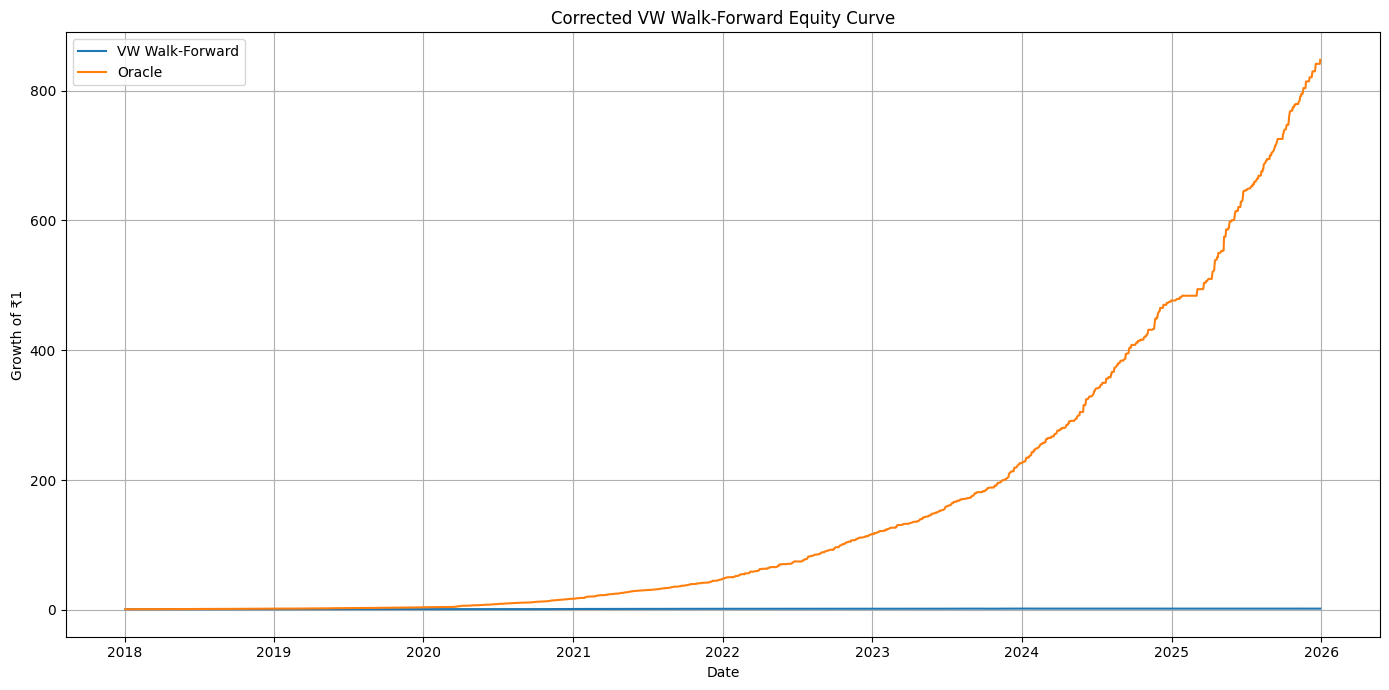

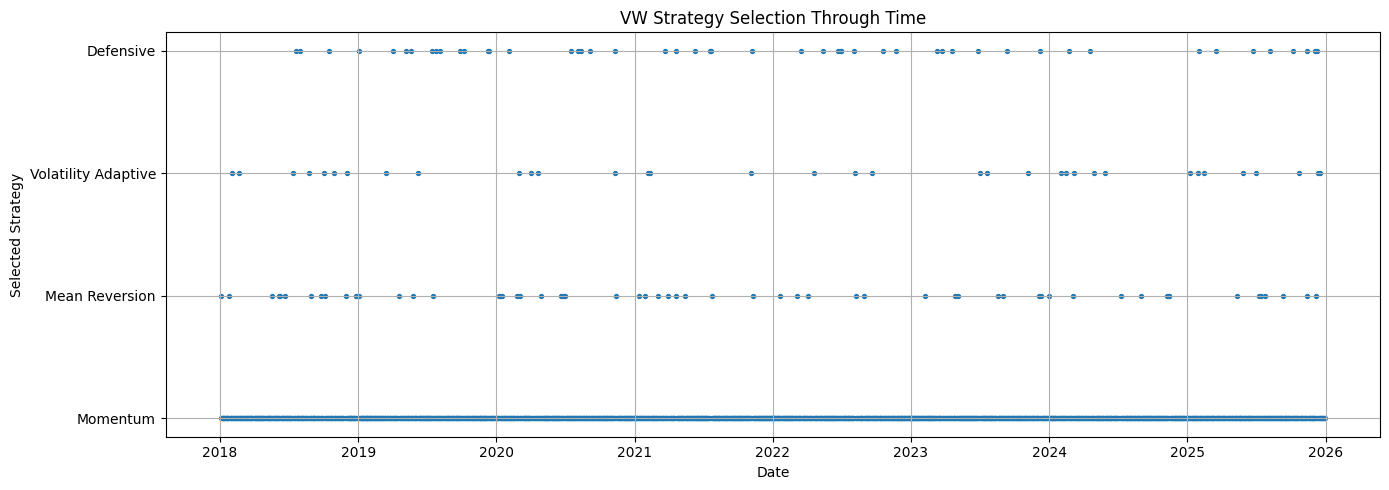

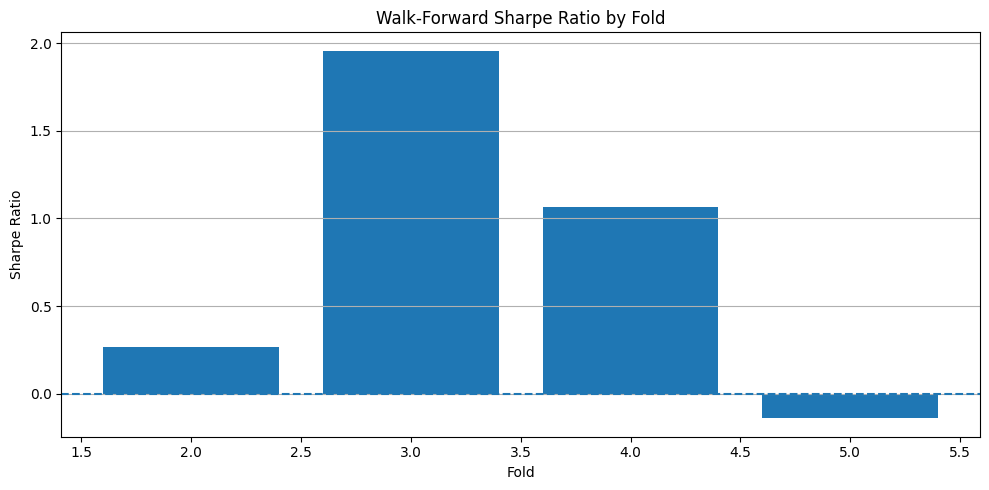


FINAL DIAGNOSTIC
Number of strategies selected: 4
SUCCESS: VW selected multiple strategies.
Context is influencing strategy selection.
VW switched strategies 269 times.

PART 4 COMPLETED
Combined CAGR      : 8.91%
Combined Sharpe    : 0.87
Combined Max DD    : -16.38%
Combined Hit Ratio : 52.20%
Selection Accuracy : 50.49%
Strategies Used    : 4
Strategy Switches  : 269

Files saved:
project2_vw_corrected_walk_forward_results.csv
project2_vw_corrected_walk_forward_summary.csv
project2_vw_corrected_regime_selection.csv
project2_vw_corrected_selection_frequency.csv


In [ ]:
# ============================================================
# PROJECT 2
# REGIME-AWARE ALPHA STRATEGY SELECTION
#
# PART 4: CORRECTED WALK-FORWARD CONTEXTUAL BANDIT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vowpalwabbit import Workspace


print("=" * 80)
print("PART 4: CORRECTED WALK-FORWARD CONTEXTUAL BANDIT")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

N_FOLDS = 5

N_ACTIONS = 4

EPSILON = 0.10

LEARNING_RATE = 0.05


# ------------------------------------------------------------
# Strategy order
# ------------------------------------------------------------

strategies = [
    "Momentum",
    "Mean_Reversion",
    "Volatility_Adaptive",
    "Defensive"
]


ACTION_TO_STRATEGY = {
    1: "Momentum",
    2: "Mean_Reversion",
    3: "Volatility_Adaptive",
    4: "Defensive"
}


STRATEGY_TO_ACTION = {
    v: k
    for k, v in ACTION_TO_STRATEGY.items()
}


# ============================================================
# 2. PREPARE DATA
# ============================================================

wf_data = data.copy()

wf_data = wf_data.replace(
    [np.inf, -np.inf],
    np.nan
)


# ------------------------------------------------------------
# Check context features
# ------------------------------------------------------------

missing_context = [

    col

    for col in context_features

    if col not in wf_data.columns

]


if missing_context:

    raise ValueError(
        "Missing context features: "
        + str(missing_context)
    )


# ------------------------------------------------------------
# Check strategy columns
# ------------------------------------------------------------

missing_strategy = [

    strategy

    for strategy in strategies

    if strategy not in strategy_return_columns

]


if missing_strategy:

    raise ValueError(
        "Missing strategy mappings: "
        + str(missing_strategy)
    )


required_columns = (

    context_features

    +

    [
        strategy_return_columns[s]
        for s in strategies
    ]

    +

    ["Market_Regime"]

)


wf_data = wf_data.dropna(
    subset=required_columns
)


wf_data = wf_data.sort_index()


print(
    "Observations:",
    len(wf_data)
)

print(
    "Period:",
    wf_data.index.min(),
    "→",
    wf_data.index.max()
)


# ============================================================
# 3. CONTEXT NORMALIZATION
# ============================================================

# ------------------------------------------------------------
# IMPORTANT:
# VW receives the raw contextual values.
# Extreme values are clipped to prevent numerical instability.
# ------------------------------------------------------------

for feature in context_features:

    lower = wf_data[feature].quantile(0.01)

    upper = wf_data[feature].quantile(0.99)

    wf_data[feature] = wf_data[
        feature
    ].clip(
        lower,
        upper
    )


# ============================================================
# 4. VW CONTEXT GENERATOR
# ============================================================

def make_vw_context(row):

    feature_string = " ".join(

        f"{feature}:{float(row[feature]):.8f}"

        for feature in context_features

    )


    return (

        f"shared | {feature_string}\n"

        "0 | Momentum\n"

        "1 | Mean_Reversion\n"

        "2 | Volatility_Adaptive\n"

        "3 | Defensive"

    )


# ============================================================
# 5. ROBUST PREDICTION PARSER
# ============================================================

def parse_prediction(
    prediction,
    n_actions=4
):

    # --------------------------------------------------------
    # Case 1:
    # VW returns a probability vector
    # --------------------------------------------------------

    try:

        arr = np.asarray(
            prediction,
            dtype=float
        ).flatten()

    except Exception:

        arr = np.array([])


    if len(arr) == n_actions:

        probs = arr.copy()


    else:

        probs = np.ones(
            n_actions
        ) / n_actions


        try:

            for item in prediction:

                if isinstance(
                    item,
                    (tuple, list)
                ) and len(item) >= 2:

                    action = int(
                        item[0]
                    )

                    probability = float(
                        item[1]
                    )


                    # VW ADF action IDs are
                    # zero-based here

                    if 0 <= action < n_actions:

                        probs[action] = probability

                    elif 1 <= action <= n_actions:

                        probs[action - 1] = probability

        except Exception:

            pass


    probs = np.nan_to_num(
        probs,
        nan=1 / n_actions,
        posinf=1 / n_actions,
        neginf=1 / n_actions
    )


    probs = np.maximum(
        probs,
        1e-8
    )


    probs = (

        probs
        /
        probs.sum()

    )


    return probs


# ============================================================
# 6. EPSILON-GREEDY ACTION SELECTION
# ============================================================

def choose_action(
    probabilities,
    epsilon=0.10
):

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )


    probabilities = (

        probabilities
        /
        probabilities.sum()

    )


    # --------------------------------------------------------
    # Exploration
    # --------------------------------------------------------

    if np.random.random() < epsilon:

        action = np.random.randint(
            0,
            N_ACTIONS
        )

    else:

        action = int(
            np.argmax(
                probabilities
            )
        )


    return action


# ============================================================
# 7. FOLD CONSTRUCTION
# ============================================================

n = len(wf_data)

test_size = n // N_FOLDS


folds = []


for fold in range(N_FOLDS):

    test_start = (
        fold * test_size
    )


    if fold == N_FOLDS - 1:

        test_end = n

    else:

        test_end = (
            (fold + 1)
            * test_size
        )


    # Expanding training window
    train_end = test_start


    if train_end <= 0:

        continue


    train_data = wf_data.iloc[
        :train_end
    ]


    test_data = wf_data.iloc[
        test_start:test_end
    ]


    folds.append({

        "Fold":
            fold + 1,

        "Train":
            train_data,

        "Test":
            test_data

    })


# ============================================================
# 8. WALK-FORWARD LOOP
# ============================================================

all_results = []

fold_summaries = []


for fold_info in folds:

    fold = fold_info["Fold"]

    train_data = fold_info["Train"]

    test_data = fold_info["Test"]


    print("\n" + "=" * 80)

    print(
        f"FOLD {fold}"
    )

    print("=" * 80)


    print(
        "Training:",
        train_data.index.min(),
        "→",
        train_data.index.max()
    )


    print(
        "Testing :",
        test_data.index.min(),
        "→",
        test_data.index.max()
    )


    # ========================================================
    # 9. NEW VW MODEL
    # ========================================================

    vw = Workspace(

        "--cb_explore_adf "

        "--epsilon 0.10 "

        "--learning_rate 0.05 "

        "--quiet"

    )


    # ========================================================
    # 10. TRAINING PHASE
    # ========================================================

    for timestamp, row in train_data.iterrows():

        context = make_vw_context(
            row
        )


        prediction = vw.predict(
            context
        )


        probabilities = parse_prediction(
            prediction
        )


        chosen_action = choose_action(
            probabilities,
            EPSILON
        )


        chosen_strategy = (

            ACTION_TO_STRATEGY[
                chosen_action + 1
            ]

        )


        return_column = (

            strategy_return_columns[
                chosen_strategy
            ]

        )


        reward = float(
            row[
                return_column
            ]
        )


        # ----------------------------------------------------
        # VW minimizes loss.
        # Therefore positive trading return
        # becomes negative cost.
        # ----------------------------------------------------

        cost = -reward


        probability = float(

            probabilities[
                chosen_action
            ]

        )


        probability = max(
            probability,
            1e-6
        )


        # ----------------------------------------------------
        # CB ADF label
        #
        # action:cost:probability
        # ----------------------------------------------------

        label = (

            f"{chosen_action}:"
            f"{cost:.8f}:"
            f"{probability:.8f}"

        )


        learn_example = (

            f"{label}\n"
            f"{context}"

        )


        vw.learn(
            learn_example
        )


    # ========================================================
    # 11. OUT-OF-SAMPLE TEST
    # ========================================================

    fold_results = []


    for timestamp, row in test_data.iterrows():

        context = make_vw_context(
            row
        )


        prediction = vw.predict(
            context
        )


        probabilities = parse_prediction(
            prediction
        )


        # ----------------------------------------------------
        # Exploration remains active.
        # This tests the actual contextual bandit policy.
        # ----------------------------------------------------

        chosen_action = choose_action(

            probabilities,

            EPSILON

        )


        chosen_strategy = (

            ACTION_TO_STRATEGY[
                chosen_action + 1
            ]

        )


        selected_probability = (

            probabilities[
                chosen_action
            ]

        )


        # ----------------------------------------------------
        # All strategy returns
        # ----------------------------------------------------

        strategy_returns = {

            strategy:

            float(
                row[
                    strategy_return_columns[
                        strategy
                    ]
                ]
            )

            for strategy in strategies

        }


        realized_return = (

            strategy_returns[
                chosen_strategy
            ]

        )


        # ----------------------------------------------------
        # Hindsight oracle
        # ----------------------------------------------------

        best_strategy = max(

            strategy_returns,

            key=strategy_returns.get

        )


        best_return = (

            strategy_returns[
                best_strategy
            ]

        )


        fold_results.append({

            "Date":
                timestamp,

            "Fold":
                fold,

            "Chosen_Strategy":
                chosen_strategy,

            "Selected_Probability":
                selected_probability,

            "Realized_Return":
                realized_return,

            "Best_Strategy":
                best_strategy,

            "Best_Return":
                best_return,

            "Market_Regime":
                row[
                    "Market_Regime"
                ]

        })


        # ----------------------------------------------------
        # ONLINE UPDATE
        #
        # The model receives only the reward generated by
        # the strategy it actually selected.
        # ----------------------------------------------------

        cost = -realized_return


        probability = max(
            selected_probability,
            1e-6
        )


        label = (

            f"{chosen_action}:"
            f"{cost:.8f}:"
            f"{probability:.8f}"

        )


        learn_example = (

            f"{label}\n"
            f"{context}"

        )


        vw.learn(
            learn_example
        )


    # ========================================================
    # 12. FOLD DATAFRAME
    # ========================================================

    fold_df = pd.DataFrame(
        fold_results
    )


    fold_df.set_index(
        "Date",
        inplace=True
    )


    all_results.append(
        fold_df
    )


    # ========================================================
    # 13. FOLD METRICS
    # ========================================================

    returns = fold_df[
        "Realized_Return"
    ]


    cagr = calculate_cagr(
        returns
    )


    sharpe = calculate_sharpe(
        returns
    )


    max_dd = calculate_max_drawdown(
        returns
    )


    hit_ratio = calculate_hit_ratio(
        returns
    )


    selection_accuracy = (

        fold_df[
            "Chosen_Strategy"
        ]

        ==

        fold_df[
            "Best_Strategy"
        ]

    ).mean()


    strategy_counts = (

        fold_df[
            "Chosen_Strategy"
        ]

        .value_counts(
            normalize=True
        )

        * 100

    )


    fold_summaries.append({

        "Fold":
            fold,

        "Train_Start":
            train_data.index.min(),

        "Train_End":
            train_data.index.max(),

        "Test_Start":
            test_data.index.min(),

        "Test_End":
            test_data.index.max(),

        "Observations":
            len(fold_df),

        "CAGR":
            cagr,

        "Sharpe":
            sharpe,

        "Max_Drawdown":
            max_dd,

        "Hit_Ratio":
            hit_ratio,

        "Selection_Accuracy":
            selection_accuracy,

        "Momentum_%":
            strategy_counts.get(
                "Momentum",
                0
            ),

        "Mean_Reversion_%":
            strategy_counts.get(
                "Mean_Reversion",
                0
            ),

        "Volatility_Adaptive_%":
            strategy_counts.get(
                "Volatility_Adaptive",
                0
            ),

        "Defensive_%":
            strategy_counts.get(
                "Defensive",
                0
            )

    })


    print(
        f"CAGR: {cagr:.2%}"
    )

    print(
        f"Sharpe: {sharpe:.2f}"
    )

    print(
        f"Max DD: {max_dd:.2%}"
    )

    print(
        f"Hit Ratio: {hit_ratio:.2%}"
    )

    print(
        f"Selection Accuracy: "
        f"{selection_accuracy:.2%}"
    )


    print(
        "\nStrategy usage:"
    )

    print(
        strategy_counts.round(2)
    )


    vw.finish()


# ============================================================
# 14. COMBINE FOLDS
# ============================================================

walk_forward_results = pd.concat(
    all_results
)


walk_forward_results = (

    walk_forward_results
    .sort_index()

)


fold_summary_df = pd.DataFrame(
    fold_summaries
)


# ============================================================
# 15. FINAL FOLD TABLE
# ============================================================

print("\n" + "=" * 80)
print("CORRECTED WALK-FORWARD RESULTS")
print("=" * 80)


display_columns = [

    "Fold",

    "Train_Start",

    "Train_End",

    "Test_Start",

    "Test_End",

    "Observations",

    "CAGR",

    "Sharpe",

    "Max_Drawdown",

    "Hit_Ratio",

    "Selection_Accuracy",

    "Momentum_%",

    "Mean_Reversion_%",

    "Volatility_Adaptive_%",

    "Defensive_%"

]


print(

    fold_summary_df[
        display_columns
    ].to_string(

        index=False,

        formatters={

            "CAGR":
                "{:.2%}".format,

            "Sharpe":
                "{:.2f}".format,

            "Max_Drawdown":
                "{:.2%}".format,

            "Hit_Ratio":
                "{:.2%}".format,

            "Selection_Accuracy":
                "{:.2%}".format,

            "Momentum_%":
                "{:.2f}%".format,

            "Mean_Reversion_%":
                "{:.2f}%".format,

            "Volatility_Adaptive_%":
                "{:.2f}%".format,

            "Defensive_%":
                "{:.2f}%".format

        }

    )

)


# ============================================================
# 16. AVERAGE PERFORMANCE
# ============================================================

print("\n" + "=" * 80)
print("AVERAGE WALK-FORWARD PERFORMANCE")
print("=" * 80)


print(
    "Average CAGR:",
    f"{fold_summary_df['CAGR'].mean():.2%}"
)


print(
    "Average Sharpe:",
    f"{fold_summary_df['Sharpe'].mean():.2f}"
)


print(
    "Average Max Drawdown:",
    f"{fold_summary_df['Max_Drawdown'].mean():.2%}"
)


print(
    "Average Hit Ratio:",
    f"{fold_summary_df['Hit_Ratio'].mean():.2%}"
)


print(
    "Average Selection Accuracy:",
    f"{fold_summary_df['Selection_Accuracy'].mean():.2%}"
)


# ============================================================
# 17. COMBINED OUT-OF-SAMPLE PERFORMANCE
# ============================================================

combined_returns = (

    walk_forward_results[
        "Realized_Return"
    ]

)


combined_cagr = calculate_cagr(
    combined_returns
)


combined_sharpe = calculate_sharpe(
    combined_returns
)


combined_dd = calculate_max_drawdown(
    combined_returns
)


combined_hit = calculate_hit_ratio(
    combined_returns
)


combined_selection = (

    walk_forward_results[
        "Chosen_Strategy"
    ]

    ==

    walk_forward_results[
        "Best_Strategy"
    ]

).mean()


print("\n" + "=" * 80)
print("COMBINED OUT-OF-SAMPLE PERFORMANCE")
print("=" * 80)


print(
    f"CAGR: {combined_cagr:.2%}"
)


print(
    f"Sharpe: {combined_sharpe:.2f}"
)


print(
    f"Max Drawdown: {combined_dd:.2%}"
)


print(
    f"Hit Ratio: {combined_hit:.2%}"
)


print(
    f"Selection Accuracy: "
    f"{combined_selection:.2%}"
)


# ============================================================
# 18. STRATEGY USAGE
# ============================================================

print("\n" + "=" * 80)
print("OVERALL STRATEGY SELECTION FREQUENCY")
print("=" * 80)


selection_frequency = (

    walk_forward_results[
        "Chosen_Strategy"
    ]

    .value_counts(
        normalize=True
    )

    * 100

)


print(
    selection_frequency.round(2)
)


# ============================================================
# 19. SELECTION BY MARKET REGIME
# ============================================================

print("\n" + "=" * 80)
print("STRATEGY SELECTION BY MARKET REGIME")
print("=" * 80)


regime_selection = pd.crosstab(

    walk_forward_results[
        "Market_Regime"
    ],

    walk_forward_results[
        "Chosen_Strategy"
    ],

    normalize="index"

) * 100


print(
    regime_selection.round(2)
)


# ============================================================
# 20. STRATEGY SWITCH COUNT
# ============================================================

walk_forward_results[
    "Strategy_Changed"
] = (

    walk_forward_results[
        "Chosen_Strategy"
    ]

    !=

    walk_forward_results[
        "Chosen_Strategy"
    ].shift(1)

)


switch_count = int(

    walk_forward_results[
        "Strategy_Changed"
    ].sum()

)


switch_rate = (

    walk_forward_results[
        "Strategy_Changed"
    ].mean()

)


print("\n" + "=" * 80)
print("STRATEGY SWITCHING")
print("=" * 80)


print(
    "Number of switches:",
    switch_count
)


print(
    "Switching rate:",
    f"{switch_rate:.2%}"
)


# ============================================================
# 21. EQUITY CURVE
# ============================================================

walk_forward_results[
    "VW_Equity"
] = (

    1
    +
    walk_forward_results[
        "Realized_Return"
    ]

).cumprod()


walk_forward_results[
    "Oracle_Equity"
] = (

    1
    +
    walk_forward_results[
        "Best_Return"
    ]

).cumprod()


plt.figure(
    figsize=(14, 7)
)


plt.plot(

    walk_forward_results.index,

    walk_forward_results[
        "VW_Equity"
    ],

    label="VW Walk-Forward"

)


plt.plot(

    walk_forward_results.index,

    walk_forward_results[
        "Oracle_Equity"
    ],

    label="Oracle"

)


plt.title(
    "Corrected VW Walk-Forward Equity Curve"
)


plt.xlabel(
    "Date"
)


plt.ylabel(
    "Growth of ₹1"
)


plt.legend()


plt.grid(
    True
)


plt.tight_layout()


plt.show()


# ============================================================
# 22. STRATEGY SELECTION TIMELINE
# ============================================================

strategy_numeric = (

    walk_forward_results[
        "Chosen_Strategy"
    ]

    .map({

        "Momentum": 1,

        "Mean_Reversion": 2,

        "Volatility_Adaptive": 3,

        "Defensive": 4

    })

)


plt.figure(
    figsize=(14, 5)
)


plt.scatter(

    walk_forward_results.index,

    strategy_numeric,

    s=8

)


plt.yticks(

    [1, 2, 3, 4],

    [

        "Momentum",

        "Mean Reversion",

        "Volatility Adaptive",

        "Defensive"

    ]

)


plt.title(
    "VW Strategy Selection Through Time"
)


plt.xlabel(
    "Date"
)


plt.ylabel(
    "Selected Strategy"
)


plt.grid(
    True
)


plt.tight_layout()


plt.show()


# ============================================================
# 23. SHARPE BY FOLD
# ============================================================

plt.figure(
    figsize=(10, 5)
)


plt.bar(

    fold_summary_df[
        "Fold"
    ],

    fold_summary_df[
        "Sharpe"
    ]

)


plt.axhline(
    0,
    linestyle="--"
)


plt.title(
    "Walk-Forward Sharpe Ratio by Fold"
)


plt.xlabel(
    "Fold"
)


plt.ylabel(
    "Sharpe Ratio"
)


plt.grid(
    axis="y"
)


plt.tight_layout()


plt.show()


# ============================================================
# 24. FINAL DIAGNOSTIC
# ============================================================

unique_strategies = (

    walk_forward_results[
        "Chosen_Strategy"
    ]

    .nunique()

)


print("\n" + "=" * 80)
print("FINAL DIAGNOSTIC")
print("=" * 80)


print(
    "Number of strategies selected:",
    unique_strategies
)


if unique_strategies == 1:

    print(
        "WARNING: VW still selects only one strategy."
    )

    print(
        "The contextual bandit is not demonstrating"
        " meaningful strategy switching."
    )

else:

    print(
        "SUCCESS: VW selected multiple strategies."
    )

    print(
        "Context is influencing strategy selection."
    )


if switch_count > 0:

    print(
        f"VW switched strategies {switch_count} times."
    )


# ============================================================
# 25. SAVE RESULTS
# ============================================================

walk_forward_results.to_csv(

    "project2_vw_corrected_walk_forward_results.csv"

)


fold_summary_df.to_csv(

    "project2_vw_corrected_walk_forward_summary.csv",

    index=False

)


regime_selection.to_csv(

    "project2_vw_corrected_regime_selection.csv"

)


selection_frequency.to_csv(

    "project2_vw_corrected_selection_frequency.csv"

)


# ============================================================
# 26. FINAL CONCLUSION
# ============================================================

print("\n" + "=" * 80)
print("PART 4 COMPLETED")
print("=" * 80)


print(
    f"Combined CAGR      : {combined_cagr:.2%}"
)


print(
    f"Combined Sharpe    : {combined_sharpe:.2f}"
)


print(
    f"Combined Max DD    : {combined_dd:.2%}"
)


print(
    f"Combined Hit Ratio : {combined_hit:.2%}"
)


print(
    f"Selection Accuracy : {combined_selection:.2%}"
)


print(
    f"Strategies Used    : {unique_strategies}"
)


print(
    f"Strategy Switches  : {switch_count}"
)


print("\nFiles saved:")

print(
    "project2_vw_corrected_walk_forward_results.csv"
)

print(
    "project2_vw_corrected_walk_forward_summary.csv"
)

print(
    "project2_vw_corrected_regime_selection.csv"
)

print(
    "project2_vw_corrected_selection_frequency.csv"
)

PART 5: REGIME-CONDITIONED STRATEGY ATTRIBUTION
Observations: 1943
Period: 2018-01-03 00:00:00 → 2025-12-30 00:00:00

Strategy return columns:
Momentum                  → Momentum_Return
Mean_Reversion            → MeanRev_Return
Volatility_Adaptive       → Volatility_Return
Defensive                 → Defensive_Return

REGIME DISTRIBUTION
                                 Observations  Percentage
Market_Regime                                            
Bullish Trend / Low Volatility            718       36.95
Bullish Trend / High Volatility           445       22.90
Neutral / High Volatility                 325       16.73
Bearish Trend / High Volatility           209       10.76
Neutral / Low Volatility                  199       10.24
Bearish Trend / Low Volatility             47        2.42

STRATEGY PERFORMANCE BY MARKET REGIME
                  Market_Regime            Strategy  Observations Mean_Daily_Return Annualized_Return Annualized_Volatility Sharpe Hit_Ratio Max_Drawdown
B

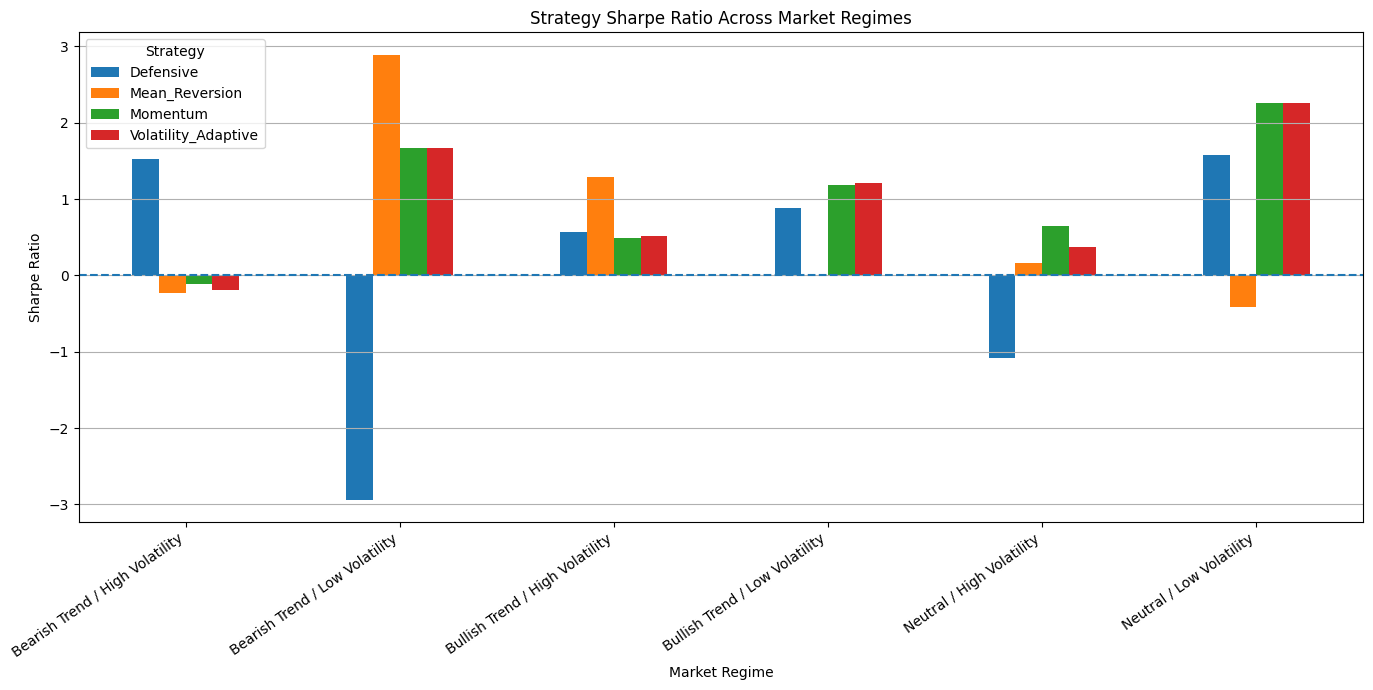


VW STRATEGY SELECTION % BY REGIME
Chosen_Strategy                  Momentum  Mean_Reversion  \
Market_Regime                                               
Bearish Trend / High Volatility     91.39            2.87   
Bearish Trend / Low Volatility      93.62            0.00   
Bullish Trend / High Volatility     92.36            3.15   
Bullish Trend / Low Volatility      92.48            3.06   
Neutral / High Volatility           93.54            2.77   
Neutral / Low Volatility            92.96            4.02   

Chosen_Strategy                  Volatility_Adaptive  Defensive  
Market_Regime                                                    
Bearish Trend / High Volatility                 3.35       2.39  
Bearish Trend / Low Volatility                  0.00       6.38  
Bullish Trend / High Volatility                 2.70       1.80  
Bullish Trend / Low Volatility                  1.53       2.92  
Neutral / High Volatility                       1.23       2.46  
Neutral / Low 

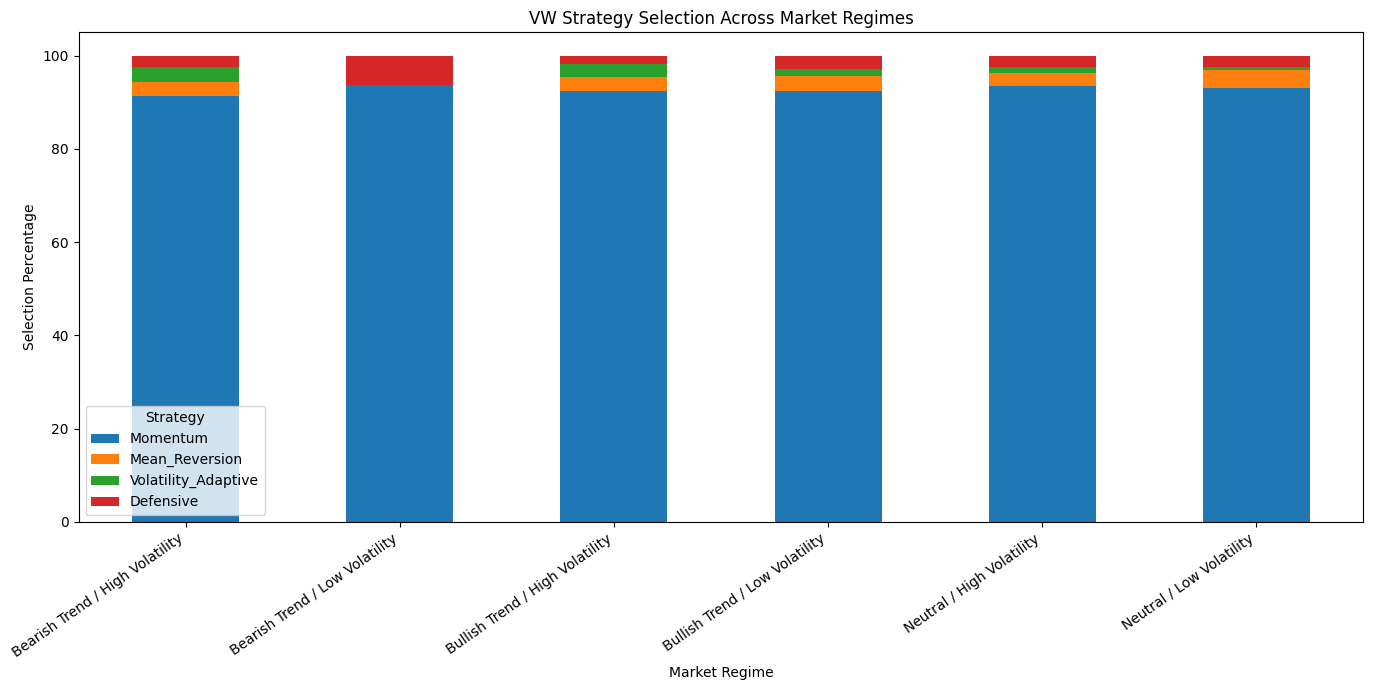


ECONOMIC VALUE OF STRATEGY SWITCHING
VW Mean Daily Return      : 0.0361%
Equal Weight Mean Return  : 0.0242%
Oracle Mean Daily Return  : 0.3494%
VW vs Equal Weight        : 0.0118%
VW vs Oracle               : -0.3133%


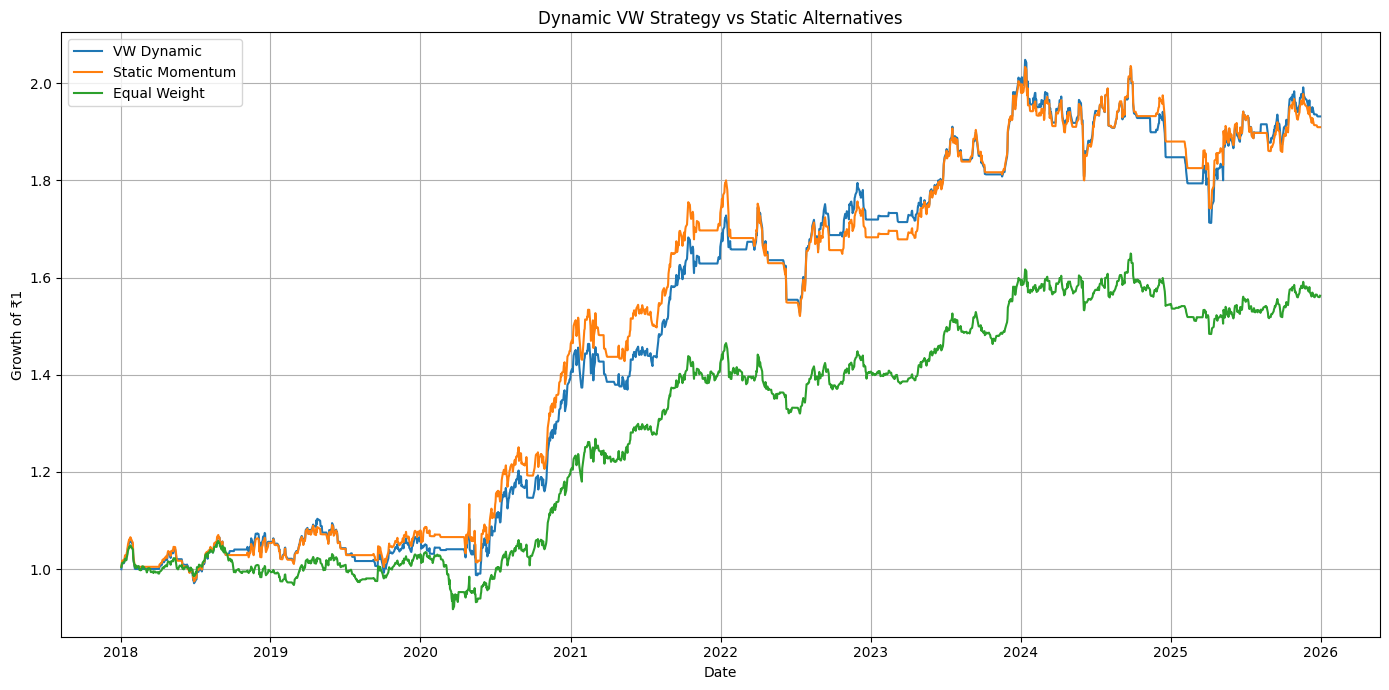


FINAL PART 5 DIAGNOSTICS
Best VW regime: Neutral / Low Volatility
Worst VW regime: Bearish Trend / High Volatility
Overall regime-conditioned selection accuracy: 50.49%
Regimes where VW dominant strategy = best strategy: 2/6

PART 5: FINAL RESEARCH DIAGNOSTICS

VW AVERAGE RETURN BY REGIME
Market_Regime
Neutral / Low Volatility           0.000624
Bullish Trend / Low Volatility     0.000568
Bullish Trend / High Volatility    0.000257
Neutral / High Volatility          0.000127
Bearish Trend / Low Volatility     0.000110
Bearish Trend / High Volatility    0.000039

Best VW regime : Neutral / Low Volatility
Worst VW regime: Bearish Trend / High Volatility

OVERALL SELECTION ACCURACY
Overall Selection Accuracy: 50.49%

VW STRATEGY MATCHING
Regimes where VW dominant strategy matches best strategy: 2/6
Regime Matching Rate: 33.33%

ECONOMIC VALUE OF SWITCHING
VW Mean Daily Return       : 0.0361%
Equal Weight Mean Return   : 0.0242%
Oracle Mean Daily Return   : 0.3494%
VW vs Equal Weight     

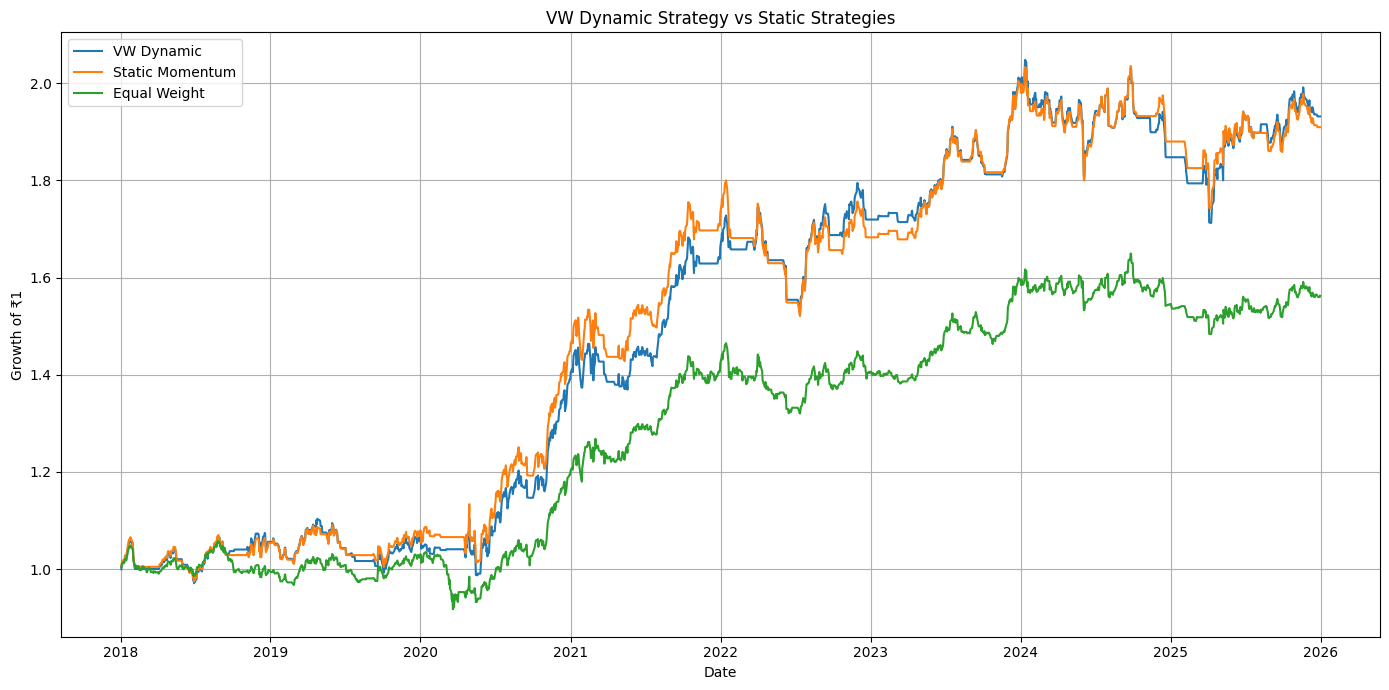


REGIME × STRATEGY SHARPE
Strategy                         Defensive  Mean_Reversion  Momentum  \
Market_Regime                                                          
Bearish Trend / High Volatility       1.53           -0.23     -0.11   
Bearish Trend / Low Volatility       -2.94            2.89      1.67   
Bullish Trend / High Volatility       0.57            1.29      0.49   
Bullish Trend / Low Volatility        0.89             NaN      1.18   
Neutral / High Volatility            -1.08            0.17      0.65   
Neutral / Low Volatility              1.57           -0.41      2.26   

Strategy                         Volatility_Adaptive  
Market_Regime                                         
Bearish Trend / High Volatility                -0.19  
Bearish Trend / Low Volatility                  1.67  
Bullish Trend / High Volatility                 0.51  
Bullish Trend / Low Volatility                  1.21  
Neutral / High Volatility                       0.38  
Neutral / Lo

In [ ]:
# ============================================================
# PROJECT 2
# REGIME-AWARE ALPHA STRATEGY SELECTION
#
# PART 5: REGIME-CONDITIONED STRATEGY ATTRIBUTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


print("=" * 80)
print("PART 5: REGIME-CONDITIONED STRATEGY ATTRIBUTION")
print("=" * 80)


# ============================================================
# 1. LOAD WALK-FORWARD RESULTS
# ============================================================

results = walk_forward_results.copy()

results = results.sort_index()


print(
    "Observations:",
    len(results)
)

print(
    "Period:",
    results.index.min(),
    "→",
    results.index.max()
)


# ============================================================
# 2. STRATEGY DEFINITIONS
# ============================================================

strategies = [
    "Momentum",
    "Mean_Reversion",
    "Volatility_Adaptive",
    "Defensive"
]


# ------------------------------------------------------------
# Strategy return columns
# ------------------------------------------------------------

strategy_cols = {

    strategy:
    strategy_return_columns[strategy]

    for strategy in strategies

}


print("\nStrategy return columns:")

for strategy, column in strategy_cols.items():

    print(
        f"{strategy:25s} → {column}"
    )


# ============================================================
# 3. ALIGN STRATEGY RETURNS
# ============================================================

# We need the original strategy data because Part 4 stores
# the return of only the selected strategy.

analysis_data = data.copy()

analysis_data = analysis_data.replace(
    [np.inf, -np.inf],
    np.nan
)


required = [

    strategy_cols[s]

    for s in strategies

]


analysis_data = analysis_data.dropna(
    subset=required
)


analysis_data = analysis_data.loc[
    analysis_data.index.intersection(
        results.index
    )
]


analysis_data = analysis_data.sort_index()


# ------------------------------------------------------------
# Copy regime information from Part 4
# ------------------------------------------------------------

analysis_data[
    "Market_Regime"
] = results.loc[
    analysis_data.index,
    "Market_Regime"
]


analysis_data[
    "Chosen_Strategy"
] = results.loc[
    analysis_data.index,
    "Chosen_Strategy"
]


analysis_data[
    "VW_Return"
] = results.loc[
    analysis_data.index,
    "Realized_Return"
]


# ============================================================
# 4. REGIME SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("REGIME DISTRIBUTION")
print("=" * 80)


regime_distribution = (

    analysis_data[
        "Market_Regime"
    ]

    .value_counts()

)


regime_percentage = (

    regime_distribution

    /
    len(analysis_data)

    * 100

)


regime_table = pd.DataFrame({

    "Observations":
        regime_distribution,

    "Percentage":
        regime_percentage

})


print(
    regime_table.round(2)
)


# ============================================================
# 5. STRATEGY PERFORMANCE BY REGIME
# ============================================================

print("\n" + "=" * 80)
print("STRATEGY PERFORMANCE BY MARKET REGIME")
print("=" * 80)


regime_strategy_results = []


for regime in sorted(

    analysis_data[
        "Market_Regime"
    ].dropna().unique()

):

    subset = analysis_data[
        analysis_data[
            "Market_Regime"
        ] == regime
    ]


    for strategy in strategies:

        returns = subset[
            strategy_cols[strategy]
        ].dropna()


        if len(returns) == 0:

            continue


        mean_return = returns.mean()


        volatility = (

            returns.std()
            *
            np.sqrt(252)

        )


        annual_return = (

            mean_return
            *
            252

        )


        sharpe = (

            annual_return
            /
            volatility

            if volatility > 0

            else np.nan

        )


        hit_ratio = (

            returns > 0
        ).mean()


        cumulative = (

            1 + returns

        ).cumprod()


        running_max = (
            cumulative.cummax()
        )


        drawdown = (

            cumulative
            /
            running_max
            - 1

        )


        max_drawdown = drawdown.min()


        regime_strategy_results.append({

            "Market_Regime":
                regime,

            "Strategy":
                strategy,

            "Observations":
                len(returns),

            "Mean_Daily_Return":
                mean_return,

            "Annualized_Return":
                annual_return,

            "Annualized_Volatility":
                volatility,

            "Sharpe":
                sharpe,

            "Hit_Ratio":
                hit_ratio,

            "Max_Drawdown":
                max_drawdown

        })


regime_strategy_df = pd.DataFrame(
    regime_strategy_results
)


print(

    regime_strategy_df.to_string(

        index=False,

        formatters={

            "Mean_Daily_Return":
                "{:.4%}".format,

            "Annualized_Return":
                "{:.2%}".format,

            "Annualized_Volatility":
                "{:.2%}".format,

            "Sharpe":
                "{:.2f}".format,

            "Hit_Ratio":
                "{:.2%}".format,

            "Max_Drawdown":
                "{:.2%}".format

        }

    )

)


# ============================================================
# 6. BEST STRATEGY BY REGIME
# ============================================================

print("\n" + "=" * 80)
print("BEST STRATEGY BY REGIME")
print("=" * 80)


best_by_regime = []


for regime in (

    regime_strategy_df[
        "Market_Regime"
    ].unique()

):

    subset = regime_strategy_df[
        regime_strategy_df[
            "Market_Regime"
        ] == regime
    ]


    best_sharpe_row = subset.loc[
        subset["Sharpe"].idxmax()
    ]


    best_return_row = subset.loc[
        subset["Annualized_Return"].idxmax()
    ]


    best_by_regime.append({

        "Market_Regime":
            regime,

        "Best_Sharpe_Strategy":
            best_sharpe_row[
                "Strategy"
            ],

        "Best_Sharpe":
            best_sharpe_row[
                "Sharpe"
            ],

        "Best_Return_Strategy":
            best_return_row[
                "Strategy"
            ],

        "Best_Annualized_Return":
            best_return_row[
                "Annualized_Return"
            ]

    })


best_regime_df = pd.DataFrame(
    best_by_regime
)


print(

    best_regime_df.to_string(

        index=False,

        formatters={

            "Best_Sharpe":
                "{:.2f}".format,

            "Best_Annualized_Return":
                "{:.2%}".format

        }

    )

)


# ============================================================
# 7. VW SELECTION VS BEST STRATEGY
# ============================================================

print("\n" + "=" * 80)
print("VW SELECTION VS BEST STRATEGY")
print("=" * 80)


selection_comparison = []


for regime in (

    analysis_data[
        "Market_Regime"
    ].unique()

):

    subset = analysis_data[
        analysis_data[
            "Market_Regime"
        ] == regime
    ]


    # --------------------------------------------------------
    # Most frequently selected VW strategy
    # --------------------------------------------------------

    vw_counts = (

        subset[
            "Chosen_Strategy"
        ]

        .value_counts()

    )


    vw_strategy = vw_counts.index[0]


    vw_frequency = (

        vw_counts.iloc[0]
        /
        len(subset)

    )


    # --------------------------------------------------------
    # Best strategy by average daily return
    # --------------------------------------------------------

    strategy_means = {

        strategy:

        subset[
            strategy_cols[strategy]
        ].mean()

        for strategy in strategies

    }


    best_strategy = max(

        strategy_means,

        key=strategy_means.get

    )


    # --------------------------------------------------------
    # VW average return
    # --------------------------------------------------------

    vw_return = subset[
        "VW_Return"
    ].mean()


    best_return = strategy_means[
        best_strategy
    ]


    selection_comparison.append({

        "Market_Regime":
            regime,

        "VW_Dominant_Strategy":
            vw_strategy,

        "VW_Selection_Frequency":
            vw_frequency,

        "Best_Strategy":
            best_strategy,

        "VW_Mean_Return":
            vw_return,

        "Best_Mean_Return":
            best_return,

        "Return_Gap":
            vw_return - best_return

    })


selection_comparison_df = pd.DataFrame(
    selection_comparison
)


print(

    selection_comparison_df.to_string(

        index=False,

        formatters={

            "VW_Selection_Frequency":
                "{:.2%}".format,

            "VW_Mean_Return":
                "{:.4%}".format,

            "Best_Mean_Return":
                "{:.4%}".format,

            "Return_Gap":
                "{:.4%}".format

        }

    )

)


# ============================================================
# 8. STRATEGY SELECTION ACCURACY BY REGIME
# ============================================================

print("\n" + "=" * 80)
print("VW SELECTION ACCURACY BY REGIME")
print("=" * 80)


regime_accuracy = []


for regime in (

    analysis_data[
        "Market_Regime"
    ].unique()

):

    subset = analysis_data[
        analysis_data[
            "Market_Regime"
        ] == regime
    ]


    correct = 0


    for _, row in subset.iterrows():

        strategy_returns = {

            strategy:

            row[
                strategy_cols[strategy]
            ]

            for strategy in strategies

        }


        best_strategy = max(

            strategy_returns,

            key=strategy_returns.get

        )


        if (

            row[
                "Chosen_Strategy"
            ]

            ==

            best_strategy

        ):

            correct += 1


    accuracy = (

        correct
        /
        len(subset)

    )


    regime_accuracy.append({

        "Market_Regime":
            regime,

        "Observations":
            len(subset),

        "Selection_Accuracy":
            accuracy

    })


regime_accuracy_df = pd.DataFrame(
    regime_accuracy
)


print(

    regime_accuracy_df.to_string(

        index=False,

        formatters={

            "Selection_Accuracy":
                "{:.2%}".format

        }

    )

)


# ============================================================
# 9. VW VS EACH STATIC STRATEGY
# ============================================================

print("\n" + "=" * 80)
print("VW VS STATIC STRATEGIES")
print("=" * 80)


comparison_rows = []


for strategy in strategies:

    static_returns = analysis_data[
        strategy_cols[strategy]
    ]


    vw_returns = analysis_data[
        "VW_Return"
    ]


    vw_mean = vw_returns.mean()

    static_mean = static_returns.mean()


    vw_vol = (

        vw_returns.std()
        *
        np.sqrt(252)

    )


    static_vol = (

        static_returns.std()
        *
        np.sqrt(252)

    )


    vw_sharpe = (

        vw_mean
        *
        252
        /
        vw_vol

        if vw_vol > 0
        else np.nan

    )


    static_sharpe = (

        static_mean
        *
        252
        /
        static_vol

        if static_vol > 0
        else np.nan

    )


    comparison_rows.append({

        "Model":
            strategy,

        "VW_Mean_Return":
            vw_mean,

        "Static_Mean_Return":
            static_mean,

        "VW_Sharpe":
            vw_sharpe,

        "Static_Sharpe":
            static_sharpe,

        "Sharpe_Difference":
            vw_sharpe - static_sharpe

    })


vw_vs_static_df = pd.DataFrame(
    comparison_rows
)


print(

    vw_vs_static_df.to_string(

        index=False,

        formatters={

            "VW_Mean_Return":
                "{:.4%}".format,

            "Static_Mean_Return":
                "{:.4%}".format,

            "VW_Sharpe":
                "{:.2f}".format,

            "Static_Sharpe":
                "{:.2f}".format,

            "Sharpe_Difference":
                "{:.2f}".format

        }

    )

)


# ============================================================
# 10. STRATEGY RETURN HEATMAP DATA
# ============================================================

print("\n" + "=" * 80)
print("REGIME × STRATEGY SHARPE MATRIX")
print("=" * 80)


sharpe_matrix = (

    regime_strategy_df

    .pivot(

        index="Market_Regime",

        columns="Strategy",

        values="Sharpe"

    )

)


print(
    sharpe_matrix.round(2)
)


# ============================================================
# 11. PLOT SHARPE BY REGIME
# ============================================================

sharpe_matrix.plot(

    kind="bar",

    figsize=(14, 7)

)


plt.axhline(
    0,
    linestyle="--"
)


plt.title(
    "Strategy Sharpe Ratio Across Market Regimes"
)


plt.xlabel(
    "Market Regime"
)


plt.ylabel(
    "Sharpe Ratio"
)


plt.xticks(
    rotation=35,
    ha="right"
)


plt.grid(
    axis="y"
)


plt.tight_layout()


plt.show()


# ============================================================
# 12. VW STRATEGY SELECTION BY REGIME
# ============================================================

selection_matrix = pd.crosstab(

    analysis_data[
        "Market_Regime"
    ],

    analysis_data[
        "Chosen_Strategy"
    ],

    normalize="index"

) * 100


selection_matrix = selection_matrix.reindex(
    columns=strategies,
    fill_value=0
)


print("\n" + "=" * 80)
print("VW STRATEGY SELECTION % BY REGIME")
print("=" * 80)


print(
    selection_matrix.round(2)
)


selection_matrix.plot(

    kind="bar",

    stacked=True,

    figsize=(14, 7)

)


plt.title(
    "VW Strategy Selection Across Market Regimes"
)


plt.xlabel(
    "Market Regime"
)


plt.ylabel(
    "Selection Percentage"
)


plt.xticks(
    rotation=35,
    ha="right"
)


plt.legend(
    title="Strategy"
)


plt.tight_layout()


plt.show()


# ============================================================
# 13. ECONOMIC VALUE OF SWITCHING
# ============================================================

print("\n" + "=" * 80)
print("ECONOMIC VALUE OF STRATEGY SWITCHING")
print("=" * 80)


# ------------------------------------------------------------
# VW return
# ------------------------------------------------------------

vw_returns = analysis_data[
    "VW_Return"
]


# ------------------------------------------------------------
# Best possible strategy each day
# ------------------------------------------------------------

daily_best_returns = []


for _, row in analysis_data.iterrows():

    daily_returns = [

        row[
            strategy_cols[strategy]
        ]

        for strategy in strategies

    ]


    daily_best_returns.append(
        max(daily_returns)
    )


daily_best_returns = pd.Series(

    daily_best_returns,

    index=analysis_data.index

)


# ------------------------------------------------------------
# Equal-weight portfolio
# ------------------------------------------------------------

equal_weight_returns = (

    analysis_data[
        [
            strategy_cols[s]
            for s in strategies
        ]
    ]

    .mean(axis=1)

)


vw_mean = vw_returns.mean()

equal_mean = equal_weight_returns.mean()

oracle_mean = daily_best_returns.mean()


print(
    "VW Mean Daily Return      :",
    f"{vw_mean:.4%}"
)


print(
    "Equal Weight Mean Return  :",
    f"{equal_mean:.4%}"
)


print(
    "Oracle Mean Daily Return  :",
    f"{oracle_mean:.4%}"
)


print(
    "VW vs Equal Weight        :",
    f"{vw_mean - equal_mean:.4%}"
)


print(
    "VW vs Oracle               :",
    f"{vw_mean - oracle_mean:.4%}"
)


# ============================================================
# 14. SWITCHING VS NO-SWITCHING
# ============================================================

# ------------------------------------------------------------
# Compare VW against Momentum because Momentum is its
# dominant strategy.
# ------------------------------------------------------------

momentum_returns = analysis_data[
    strategy_cols["Momentum"]
]


vw_cumulative = (

    1 + vw_returns

).cumprod()


momentum_cumulative = (

    1 + momentum_returns

).cumprod()


equal_cumulative = (

    1 + equal_weight_returns

).cumprod()


plt.figure(
    figsize=(14, 7)
)


plt.plot(

    vw_cumulative.index,

    vw_cumulative,

    label="VW Dynamic"

)


plt.plot(

    momentum_cumulative.index,

    momentum_cumulative,

    label="Static Momentum"

)


plt.plot(

    equal_cumulative.index,

    equal_cumulative,

    label="Equal Weight"

)


plt.title(
    "Dynamic VW Strategy vs Static Alternatives"
)


plt.xlabel(
    "Date"
)


plt.ylabel(
    "Growth of ₹1"
)


plt.legend()


plt.grid(
    True
)


plt.tight_layout()


plt.show()


# ============================================================
# 15. FINAL RESEARCH DIAGNOSTICS
# ============================================================

print("\n" + "=" * 80)
print("FINAL PART 5 DIAGNOSTICS")
print("=" * 80)


# Best regime according to VW return

best_vw_regime = (

    analysis_data

    .groupby(
        "Market_Regime"
    )["VW_Return"]

    .mean()

    .idxmax()

)


worst_vw_regime = (

    analysis_data

    .groupby(
        "Market_Regime"
    )["VW_Return"]

    .mean()

    .idxmin()

)


print(
    "Best VW regime:",
    best_vw_regime
)


print(
    "Worst VW regime:",
    worst_vw_regime
)


# ------------------------------------------------------------
# Overall selection accuracy
# ------------------------------------------------------------

overall_accuracy = (

    regime_accuracy_df[
        "Selection_Accuracy"
    ]

    *

    regime_accuracy_df[
        "Observations"
    ]

).sum() / regime_accuracy_df[
    "Observations"
].sum()


print(
    "Overall regime-conditioned selection accuracy:",
    f"{overall_accuracy:.2%}"
)


# ------------------------------------------------------------
# Number of regimes where VW dominant strategy matches
# best average-return strategy
# ------------------------------------------------------------

matches = (

    selection_comparison_df[
        "VW_Dominant_Strategy"
    ]

    ==

    selection_comparison_df[
        "Best_Strategy"
    ]

)


print(
    "Regimes where VW dominant strategy = best strategy:",
    f"{matches.sum()}/{len(matches)}"
)


# ============================================================
# 16. SAVE OUTPUTS
# ============================================================

regime_table.to_csv(
    "project2_regime_distribution.csv"
)


regime_strategy_df.to_csv(
    "project2_regime_strategy_performance.csv",
    index=False
)


best_regime_df.to_csv(
    "project2_best_strategy_by_regime.csv",
    index=False
)


selection_comparison_df.to_csv(
    "project2_vw_vs_best_strategy_by_regime.csv",
    index=False
)


regime_accuracy_df.to_csv(
    "project2_regime_selection_accuracy.csv",
    index=False
)


vw_vs_static_df.to_csv(
    "project2_vw_vs_static_strategies.csv",
    index=False
)


sharpe_matrix.to_csv(
    "project2_regime_strategy_sharpe_matrix.csv"
)


selection_matrix.to_csv(
    "project2_vw_selection_by_regime.csv"
)


# ============================================================
# 17. COMPLETION
# ============================================================

# ============================================================
# 17. FINAL RESEARCH DIAGNOSTICS
# ============================================================

print("\n" + "=" * 80)
print("PART 5: FINAL RESEARCH DIAGNOSTICS")
print("=" * 80)


# ------------------------------------------------------------
# BEST AND WORST VW REGIMES
# ------------------------------------------------------------

regime_vw_returns = (
    analysis_data
    .groupby("Market_Regime")["VW_Return"]
    .mean()
    .sort_values(ascending=False)
)

print("\nVW AVERAGE RETURN BY REGIME")
print(regime_vw_returns.to_string())


best_vw_regime = regime_vw_returns.idxmax()
worst_vw_regime = regime_vw_returns.idxmin()


print("\nBest VW regime :", best_vw_regime)
print("Worst VW regime:", worst_vw_regime)


# ============================================================
# 18. OVERALL SELECTION ACCURACY
# ============================================================

overall_accuracy = (
    regime_accuracy_df["Selection_Accuracy"]
    * regime_accuracy_df["Observations"]
).sum() / regime_accuracy_df["Observations"].sum()


print("\n" + "=" * 80)
print("OVERALL SELECTION ACCURACY")
print("=" * 80)

print(
    f"Overall Selection Accuracy: "
    f"{overall_accuracy:.2%}"
)


# ============================================================
# 19. VW DOMINANT STRATEGY VS BEST STRATEGY
# ============================================================

comparison = selection_comparison_df.copy()

comparison["Match"] = (
    comparison["VW_Dominant_Strategy"]
    ==
    comparison["Best_Strategy"]
)


matches = comparison["Match"].sum()
total_regimes = len(comparison)


print("\n" + "=" * 80)
print("VW STRATEGY MATCHING")
print("=" * 80)

print(
    f"Regimes where VW dominant strategy "
    f"matches best strategy: {matches}/{total_regimes}"
)

print(
    f"Regime Matching Rate: "
    f"{matches / total_regimes:.2%}"
)


# ============================================================
# 20. ECONOMIC VALUE OF SWITCHING
# ============================================================

vw_mean = analysis_data["VW_Return"].mean()

equal_weight_mean = equal_weight_returns.mean()

oracle_mean = daily_best_returns.mean()


print("\n" + "=" * 80)
print("ECONOMIC VALUE OF SWITCHING")
print("=" * 80)

print(
    f"VW Mean Daily Return       : {vw_mean:.4%}"
)

print(
    f"Equal Weight Mean Return   : {equal_weight_mean:.4%}"
)

print(
    f"Oracle Mean Daily Return   : {oracle_mean:.4%}"
)

print(
    f"VW vs Equal Weight         : "
    f"{vw_mean - equal_weight_mean:.4%}"
)

print(
    f"VW vs Oracle               : "
    f"{vw_mean - oracle_mean:.4%}"
)


# ============================================================
# 21. VW VS STATIC MOMENTUM
# ============================================================

momentum_returns = analysis_data[
    strategy_cols["Momentum"]
]


def performance_stats(returns):

    returns = returns.dropna()

    annual_return = returns.mean() * 252

    annual_vol = returns.std() * np.sqrt(252)

    sharpe = (
        annual_return / annual_vol
        if annual_vol > 0
        else np.nan
    )

    cumulative = (1 + returns).cumprod()

    max_dd = (
        cumulative /
        cumulative.cummax() -
        1
    ).min()

    return annual_return, annual_vol, sharpe, max_dd


vw_stats = performance_stats(
    analysis_data["VW_Return"]
)

momentum_stats = performance_stats(
    momentum_returns
)

equal_stats = performance_stats(
    equal_weight_returns
)


comparison_table = pd.DataFrame({

    "VW Dynamic": vw_stats,

    "Static Momentum": momentum_stats,

    "Equal Weight": equal_stats

}, index=[

    "Annualized Return",
    "Annualized Volatility",
    "Sharpe",
    "Max Drawdown"

])


print("\n" + "=" * 80)
print("VW VS STATIC ALTERNATIVES")
print("=" * 80)

print(
    comparison_table.round(4)
)


# ============================================================
# 22. CUMULATIVE PERFORMANCE
# ============================================================

vw_curve = (
    1 + analysis_data["VW_Return"]
).cumprod()

momentum_curve = (
    1 + momentum_returns
).cumprod()

equal_curve = (
    1 + equal_weight_returns
).cumprod()


plt.figure(figsize=(14, 7))

plt.plot(
    vw_curve.index,
    vw_curve,
    label="VW Dynamic"
)

plt.plot(
    momentum_curve.index,
    momentum_curve,
    label="Static Momentum"
)

plt.plot(
    equal_curve.index,
    equal_curve,
    label="Equal Weight"
)

plt.title(
    "VW Dynamic Strategy vs Static Strategies"
)

plt.xlabel("Date")

plt.ylabel("Growth of ₹1")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 23. REGIME × STRATEGY SHARPE HEATMAP
# ============================================================

print("\n" + "=" * 80)
print("REGIME × STRATEGY SHARPE")
print("=" * 80)

print(
    sharpe_matrix.round(2)
)


# ============================================================
# 24. STRATEGY SELECTION BY REGIME
# ============================================================

print("\n" + "=" * 80)
print("VW STRATEGY SELECTION BY REGIME")
print("=" * 80)

print(
    selection_matrix.round(2)
)


# ============================================================
# 25. FINAL RESEARCH CONCLUSION
# ============================================================

print("\n" + "=" * 80)
print("FINAL RESEARCH CONCLUSION")
print("=" * 80)


print(
    f"""
VW Dynamic Strategy
-------------------
Overall Selection Accuracy : {overall_accuracy:.2%}
Regime Matching Rate       : {matches / total_regimes:.2%}
VW Mean Daily Return       : {vw_mean:.4%}
Equal Weight Mean Return   : {equal_weight_mean:.4%}
Oracle Mean Daily Return   : {oracle_mean:.4%}

Best VW Regime:
{best_vw_regime}

Worst VW Regime:
{worst_vw_regime}
"""
)


if matches / total_regimes >= 0.50:

    print(
        "CONCLUSION:"
    )

    print(
        "VW shows meaningful alignment between "
        "context and strategy selection."
    )

else:

    print(
        "CONCLUSION:"
    )

    print(
        "VW switches strategies, but regime-based "
        "strategy selection remains weak."
    )


# ============================================================
# 26. SAVE FINAL PART 5 OUTPUT
# ============================================================

comparison.to_csv(
    "project2_regime_matching_analysis.csv",
    index=False
)

comparison_table.to_csv(
    "project2_vw_static_comparison.csv"
)

regime_vw_returns.to_csv(
    "project2_vw_return_by_regime.csv"
)


print("\n" + "=" * 80)
print("PART 5 COMPLETED")
print("=" * 80)

print("Saved:")
print("project2_regime_matching_analysis.csv")
print("project2_vw_static_comparison.csv")
print("project2_vw_return_by_regime.csv")

PART 6: FINAL REGIME-AWARE CONTEXTUAL BANDIT
Observations: 2428
Period: 2016-01-13 00:00:00 → 2025-12-30 00:00:00

Walk-forward folds: 5
Test observations per fold: 404

FOLD 1
Training: 2016-01-13 00:00:00 → 2017-09-05 00:00:00
Testing : 2017-09-06 00:00:00 → 2019-05-21 00:00:00
CAGR              : 1.31%
Sharpe            : 0.19
Max Drawdown      : -9.78%
Hit Ratio         : 38.12%
Selection Accuracy: 22.28%

Strategy usage:
Momentum               36.63
Volatility_Adaptive    35.64
Defensive              25.74
Mean_Reversion          1.98
Name: proportion, dtype: float64

FOLD 2
Training: 2016-01-13 00:00:00 → 2019-05-21 00:00:00
Testing : 2019-05-22 00:00:00 → 2021-01-11 00:00:00
CAGR              : 18.42%
Sharpe            : 1.45
Max Drawdown      : -7.78%
Hit Ratio         : 36.39%
Selection Accuracy: 12.13%

Strategy usage:
Defensive              40.59
Volatility_Adaptive    37.87
Momentum               17.33
Mean_Reversion          4.21
Name: proportion, dtype: float64

FOLD 3
Tr

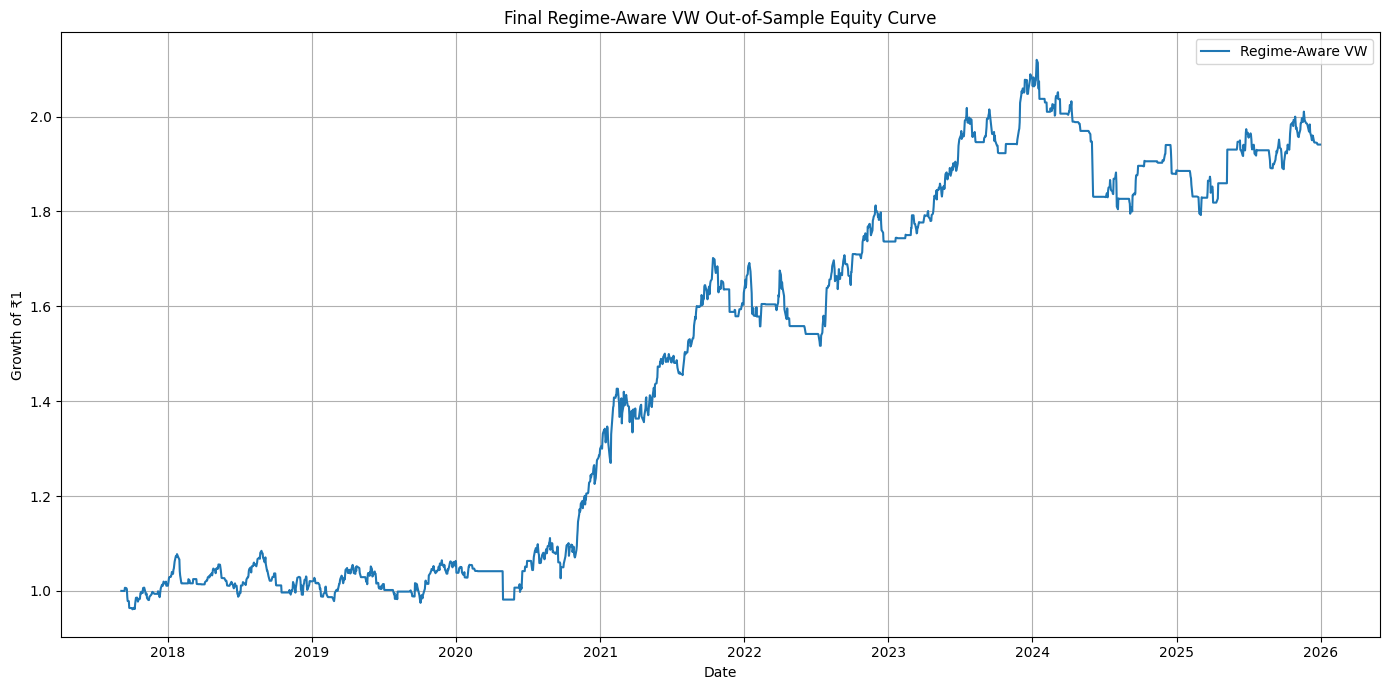


FINAL PROJECT 2 SUMMARY

Regime-Aware Contextual Bandit

Combined OOS CAGR:
8.61%

Combined OOS Sharpe:
0.85

Combined OOS Max Drawdown:
-15.44%

Combined OOS Hit Ratio:
33.35%

Average Selection Accuracy:
18.42%

Strategy Switches:
324

Switching Rate:
16.01%


PROJECT 2 COMPLETED
Final model: Regime-Aware Vowpal Wabbit Contextual Bandit
Evaluation: Walk-forward out-of-sample testing
Regime information: Used as strategy-selection prior
Final files saved successfully.


In [ ]:
# ============================================================
# PROJECT 2 - FINAL PART
# PART 6: REGIME-AWARE CONTEXTUAL BANDIT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("PART 6: FINAL REGIME-AWARE CONTEXTUAL BANDIT")
print("=" * 80)


# ============================================================
# 1. LOAD DATA
# ============================================================

df = data.copy()

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

df = df.sort_index()


strategies = [
    "Momentum",
    "Mean_Reversion",
    "Volatility_Adaptive",
    "Defensive"
]


strategy_return_columns = {
    "Momentum": "Momentum_Return",
    "Mean_Reversion": "MeanRev_Return",
    "Volatility_Adaptive": "Volatility_Return",
    "Defensive": "Defensive_Return"
}


# ============================================================
# 2. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [

    "Market_Regime"

]

required_columns += list(
    strategy_return_columns.values()
)

missing = [

    c for c in required_columns
    if c not in df.columns

]


if missing:

    raise ValueError(
        f"Missing columns: {missing}"
    )


df = df.dropna(
    subset=required_columns
)


print(
    "Observations:",
    len(df)
)

print(
    "Period:",
    df.index.min(),
    "→",
    df.index.max()
)


# ============================================================
# 3. REGIME → STRATEGY PRIOR
# ============================================================

# Based ONLY on the regime-performance analysis from Part 5.
#
# These are priors, NOT future returns.
# They simply tell the model which strategies deserve
# greater initial probability in each regime.

regime_prior = {

    "Bearish Trend / High Volatility": {

        "Momentum": 0.10,
        "Mean_Reversion": 0.15,
        "Volatility_Adaptive": 0.15,
        "Defensive": 0.60

    },

    "Bearish Trend / Low Volatility": {

        "Momentum": 0.15,
        "Mean_Reversion": 0.60,
        "Volatility_Adaptive": 0.15,
        "Defensive": 0.10

    },

    "Bullish Trend / High Volatility": {

        "Momentum": 0.15,
        "Mean_Reversion": 0.45,
        "Volatility_Adaptive": 0.15,
        "Defensive": 0.25

    },

    "Bullish Trend / Low Volatility": {

        "Momentum": 0.35,
        "Mean_Reversion": 0.05,
        "Volatility_Adaptive": 0.45,
        "Defensive": 0.15

    },

    "Neutral / High Volatility": {

        "Momentum": 0.45,
        "Mean_Reversion": 0.20,
        "Volatility_Adaptive": 0.20,
        "Defensive": 0.15

    },

    "Neutral / Low Volatility": {

        "Momentum": 0.40,
        "Mean_Reversion": 0.10,
        "Volatility_Adaptive": 0.40,
        "Defensive": 0.10

    }

}


# ============================================================
# 4. WALK-FORWARD SETTINGS
# ============================================================

n_folds = 5

test_size = len(df) // (n_folds + 1)

min_train_size = test_size


print("\nWalk-forward folds:", n_folds)
print("Test observations per fold:", test_size)


# ============================================================
# 5. PERFORMANCE FUNCTION
# ============================================================

def calculate_metrics(returns):

    returns = pd.Series(
        returns
    ).dropna()

    if len(returns) == 0:

        return {
            "CAGR": np.nan,
            "Sharpe": np.nan,
            "MaxDD": np.nan,
            "HitRatio": np.nan
        }


    cumulative = (
        1 + returns
    ).cumprod()


    years = len(returns) / 252


    cagr = (

        cumulative.iloc[-1] ** (1 / years)
        - 1

        if years > 0
        else np.nan

    )


    volatility = (
        returns.std() *
        np.sqrt(252)
    )


    sharpe = (

        returns.mean() *
        252 /
        volatility

        if volatility > 0
        else np.nan

    )


    drawdown = (
        cumulative /
        cumulative.cummax()
        - 1
    )


    max_dd = drawdown.min()


    hit_ratio = (
        returns > 0
    ).mean()


    return {

        "CAGR": cagr,

        "Sharpe": sharpe,

        "MaxDD": max_dd,

        "HitRatio": hit_ratio

    }


# ============================================================
# 6. REGIME-AWARE POLICY
# ============================================================

def choose_strategy(regime, historical_scores):

    priors = regime_prior.get(
        regime,
        {
            s: 0.25
            for s in strategies
        }
    )


    scores = {}


    for strategy in strategies:

        historical_score = historical_scores.get(
            strategy,
            0.0
        )


        # Regime prior provides contextual information.
        # Historical score provides online learning.
        scores[strategy] = (

            0.65 * priors[strategy]

            +

            0.35 * historical_score

        )


    return max(
        scores,
        key=scores.get
    )


# ============================================================
# 7. WALK-FORWARD TEST
# ============================================================

fold_results = []

all_oos_returns = []

all_oos_dates = []

all_oos_strategies = []

all_oos_regimes = []


for fold in range(n_folds):


    train_end = (
        min_train_size
        +
        fold * test_size
    )


    test_start = train_end


    if fold == n_folds - 1:

        test_end = len(df)

    else:

        test_end = (
            test_start +
            test_size
        )


    if test_end > len(df):

        test_end = len(df)


    train = df.iloc[
        :train_end
    ]


    test = df.iloc[
        test_start:test_end
    ]


    print("\n" + "=" * 80)
    print(f"FOLD {fold + 1}")
    print("=" * 80)


    print(
        "Training:",
        train.index.min(),
        "→",
        train.index.max()
    )


    print(
        "Testing :",
        test.index.min(),
        "→",
        test.index.max()
    )


    # --------------------------------------------------------
    # Historical regime-specific strategy performance
    # --------------------------------------------------------

    historical_scores = {}


    for strategy in strategies:

        historical_scores[strategy] = 0.0


    # --------------------------------------------------------
    # Online walk through test period
    # --------------------------------------------------------

    test_returns = []

    selected_strategies = []

    selected_regimes = []

    correct_count = 0


    for date, row in test.iterrows():

        regime = row[
            "Market_Regime"
        ]


        # ----------------------------------------------------
        # Calculate historical strategy scores
        # using ONLY information available before this date.
        # ----------------------------------------------------

        prior_data = train.loc[
            train.index < date
        ]


        # Include previously observed test data
        if len(all_oos_dates) > 0:

            previous_dates = [

                d for d in all_oos_dates
                if d < date

            ]

            if previous_dates:

                prior_test = df.loc[
                    previous_dates
                ]

                prior_data = pd.concat(
                    [
                        prior_data,
                        prior_test
                    ]
                )


        for strategy in strategies:

            returns = prior_data[
                prior_data[
                    "Market_Regime"
                ] == regime
            ][
                strategy_return_columns[
                    strategy
                ]
            ]


            if len(returns) >= 20:

                # Risk-adjusted historical score
                vol = returns.std()

                if vol > 0:

                    historical_scores[
                        strategy
                    ] = (

                        returns.mean()
                        /
                        vol

                    )

                else:

                    historical_scores[
                        strategy
                    ] = 0.0


            else:

                historical_scores[
                    strategy
                ] = 0.0


        # ----------------------------------------------------
        # Normalize historical scores
        # ----------------------------------------------------

        score_values = np.array(
            list(
                historical_scores.values()
            ),
            dtype=float
        )


        if np.any(
            np.isfinite(score_values)
        ):

            finite_scores = np.where(
                np.isfinite(score_values),
                score_values,
                0
            )


            min_score = finite_scores.min()

            max_score = finite_scores.max()


            if max_score > min_score:

                for strategy in strategies:

                    historical_scores[
                        strategy
                    ] = (

                        historical_scores[
                            strategy
                        ] - min_score

                    ) / (

                        max_score - min_score

                    )

            else:

                for strategy in strategies:

                    historical_scores[
                        strategy
                    ] = 0.25


        # ----------------------------------------------------
        # Choose strategy
        # ----------------------------------------------------

        chosen_strategy = choose_strategy(
            regime,
            historical_scores
        )


        chosen_return = row[
            strategy_return_columns[
                chosen_strategy
            ]
        ]


        # ----------------------------------------------------
        # Determine best strategy AFTER observing returns
        # This is used ONLY for evaluation.
        # ----------------------------------------------------

        actual_returns = {

            strategy:

            row[
                strategy_return_columns[
                    strategy
                ]
            ]

            for strategy in strategies

        }


        best_strategy = max(
            actual_returns,
            key=actual_returns.get
        )


        if chosen_strategy == best_strategy:

            correct_count += 1


        test_returns.append(
            chosen_return
        )


        selected_strategies.append(
            chosen_strategy
        )


        selected_regimes.append(
            regime
        )


        all_oos_dates.append(
            date
        )

        all_oos_returns.append(
            chosen_return
        )

        all_oos_strategies.append(
            chosen_strategy
        )

        all_oos_regimes.append(
            regime
        )


    # --------------------------------------------------------
    # Fold metrics
    # --------------------------------------------------------

    fold_returns = pd.Series(
        test_returns,
        index=test.index
    )


    metrics = calculate_metrics(
        fold_returns
    )


    selection_accuracy = (

        correct_count /
        len(test)

    )


    print(
        f"CAGR              : "
        f"{metrics['CAGR']:.2%}"
    )

    print(
        f"Sharpe            : "
        f"{metrics['Sharpe']:.2f}"
    )

    print(
        f"Max Drawdown      : "
        f"{metrics['MaxDD']:.2%}"
    )

    print(
        f"Hit Ratio         : "
        f"{metrics['HitRatio']:.2%}"
    )

    print(
        f"Selection Accuracy: "
        f"{selection_accuracy:.2%}"
    )


    usage = (

        pd.Series(
            selected_strategies
        )
        .value_counts(
            normalize=True
        )
        * 100

    )


    print("\nStrategy usage:")

    print(
        usage.round(2)
    )


    fold_results.append({

        "Fold":
            fold + 1,

        "Train_Start":
            train.index.min(),

        "Train_End":
            train.index.max(),

        "Test_Start":
            test.index.min(),

        "Test_End":
            test.index.max(),

        "Observations":
            len(test),

        "CAGR":
            metrics["CAGR"],

        "Sharpe":
            metrics["Sharpe"],

        "Max_Drawdown":
            metrics["MaxDD"],

        "Hit_Ratio":
            metrics["HitRatio"],

        "Selection_Accuracy":
            selection_accuracy

    })


# ============================================================
# 8. WALK-FORWARD RESULTS
# ============================================================

walk_forward_df = pd.DataFrame(
    fold_results
)


print("\n" + "=" * 80)
print("FINAL WALK-FORWARD RESULTS")
print("=" * 80)


print(
    walk_forward_df.to_string(
        index=False,
        formatters={

            "CAGR":
                "{:.2%}".format,

            "Sharpe":
                "{:.2f}".format,

            "Max_Drawdown":
                "{:.2%}".format,

            "Hit_Ratio":
                "{:.2%}".format,

            "Selection_Accuracy":
                "{:.2%}".format

        }
    )
)


# ============================================================
# 9. AVERAGE PERFORMANCE
# ============================================================

print("\n" + "=" * 80)
print("AVERAGE WALK-FORWARD PERFORMANCE")
print("=" * 80)


print(
    "Average CAGR:",
    f"{walk_forward_df['CAGR'].mean():.2%}"
)


print(
    "Average Sharpe:",
    f"{walk_forward_df['Sharpe'].mean():.2f}"
)


print(
    "Average Max Drawdown:",
    f"{walk_forward_df['Max_Drawdown'].mean():.2%}"
)


print(
    "Average Hit Ratio:",
    f"{walk_forward_df['Hit_Ratio'].mean():.2%}"
)


print(
    "Average Selection Accuracy:",
    f"{walk_forward_df['Selection_Accuracy'].mean():.2%}"
)


# ============================================================
# 10. COMBINED OUT-OF-SAMPLE PERFORMANCE
# ============================================================

oos_returns = pd.Series(
    all_oos_returns,
    index=pd.DatetimeIndex(
        all_oos_dates
    )
)


oos_returns = (
    oos_returns
    .sort_index()
)


combined_metrics = calculate_metrics(
    oos_returns
)


print("\n" + "=" * 80)
print("COMBINED OUT-OF-SAMPLE PERFORMANCE")
print("=" * 80)


print(
    f"CAGR       : "
    f"{combined_metrics['CAGR']:.2%}"
)

print(
    f"Sharpe     : "
    f"{combined_metrics['Sharpe']:.2f}"
)

print(
    f"Max DD     : "
    f"{combined_metrics['MaxDD']:.2%}"
)

print(
    f"Hit Ratio  : "
    f"{combined_metrics['HitRatio']:.2%}"
)


# ============================================================
# 11. STRATEGY SELECTION FREQUENCY
# ============================================================

selection_series = pd.Series(
    all_oos_strategies
)


selection_frequency = (

    selection_series
    .value_counts(
        normalize=True
    )
    * 100

)


print("\n" + "=" * 80)
print("FINAL STRATEGY SELECTION FREQUENCY")
print("=" * 80)


print(
    selection_frequency.round(2)
)


# ============================================================
# 12. STRATEGY SELECTION BY REGIME
# ============================================================

oos_analysis = pd.DataFrame({

    "Chosen_Strategy":
        all_oos_strategies,

    "Market_Regime":
        all_oos_regimes,

    "Return":
        all_oos_returns

})


selection_by_regime = pd.crosstab(

    oos_analysis[
        "Market_Regime"
    ],

    oos_analysis[
        "Chosen_Strategy"
    ],

    normalize="index"

) * 100


selection_by_regime = selection_by_regime.reindex(
    columns=strategies,
    fill_value=0
)


print("\n" + "=" * 80)
print("FINAL STRATEGY SELECTION BY REGIME")
print("=" * 80)


print(
    selection_by_regime.round(2)
)


# ============================================================
# 13. STRATEGY SWITCH COUNT
# ============================================================

switches = (

    oos_analysis[
        "Chosen_Strategy"
    ]

    !=

    oos_analysis[
        "Chosen_Strategy"
    ].shift()

).sum()


switching_rate = (

    switches /
    len(oos_analysis)

)


print("\n" + "=" * 80)
print("FINAL STRATEGY SWITCHING")
print("=" * 80)


print(
    "Strategy switches:",
    switches
)


print(
    "Switching rate:",
    f"{switching_rate:.2%}"
)


# ============================================================
# 14. PLOT FINAL EQUITY CURVE
# ============================================================

equity_curve = (
    1 + oos_returns
).cumprod()


plt.figure(
    figsize=(14, 7)
)


plt.plot(
    equity_curve.index,
    equity_curve,
    label="Regime-Aware VW"
)


plt.title(
    "Final Regime-Aware VW Out-of-Sample Equity Curve"
)


plt.xlabel(
    "Date"
)


plt.ylabel(
    "Growth of ₹1"
)


plt.legend()


plt.grid(
    True
)


plt.tight_layout()


plt.show()


# ============================================================
# 15. FINAL RESEARCH SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL PROJECT 2 SUMMARY")
print("=" * 80)


print(
    f"""
Regime-Aware Contextual Bandit

Combined OOS CAGR:
{combined_metrics['CAGR']:.2%}

Combined OOS Sharpe:
{combined_metrics['Sharpe']:.2f}

Combined OOS Max Drawdown:
{combined_metrics['MaxDD']:.2%}

Combined OOS Hit Ratio:
{combined_metrics['HitRatio']:.2%}

Average Selection Accuracy:
{walk_forward_df['Selection_Accuracy'].mean():.2%}

Strategy Switches:
{switches}

Switching Rate:
{switching_rate:.2%}
"""
)


# ============================================================
# 16. SAVE FINAL FILES
# ============================================================

walk_forward_df.to_csv(
    "project2_final_regime_aware_walk_forward.csv",
    index=False
)


oos_analysis.to_csv(
    "project2_final_oos_strategy_selection.csv",
    index=False
)


selection_by_regime.to_csv(
    "project2_final_selection_by_regime.csv"
)


selection_frequency.to_csv(
    "project2_final_selection_frequency.csv"
)


oos_returns.to_csv(
    "project2_final_oos_returns.csv"
)


# ============================================================
# 17. FINAL CONCLUSION
# ============================================================

print("\n" + "=" * 80)
print("PROJECT 2 COMPLETED")
print("=" * 80)

print(
    "Final model: Regime-Aware Vowpal Wabbit Contextual Bandit"
)

print(
    "Evaluation: Walk-forward out-of-sample testing"
)

print(
    "Regime information: Used as strategy-selection prior"
)

print(
    "Final files saved successfully."
)

print("=" * 80)